# M5: плотность выборки и ансамбли

Проверили два финалиста Optuna на 67 признаках, увеличили плотность до 52 × 28 и сравнили смеси готовых прогнозов.

Лучший сохранённый результат — **WRMSSE 0.500879**: **70% trial 9 на 52 × 28 + 30% trial 5 на 52 × 8**. Добавление CatBoost результат не улучшило; на сетке весов его доля оказалась нулевой.

| Модель | Плотность | Деревьев | WRMSSE ↓ | Bias |
|---|---:|---:|---:|---:|
| Trial 9 | 52 × 8 | 321 | 0.506104 | −0.25% |
| Trial 5 | 52 × 8 | 471 | 0.506647 | −1.04% |
| Trial 9 | 52 × 16 | 210 | 0.510333 | −0.39% |
| Trial 5 | 52 × 16 | 264 | 0.511518 | −0.68% |
| Trial 9 | 52 × 28 | 197 | 0.501959 | −0.29% |
| **Смесь LightGBM 70 / 30** | **28 + 8** | **197 + 471** | **0.500879** | **−0.52%** |

Таблица относится к **28 марта — 24 апреля 2016 года**, окну подбора. Public M5 — следующий период; места в рейтинге эти числа не определяют. Для плотности 16 числа сохранены со скриншота; точные протоколы 28 и ансамблей находятся в checkpoint.

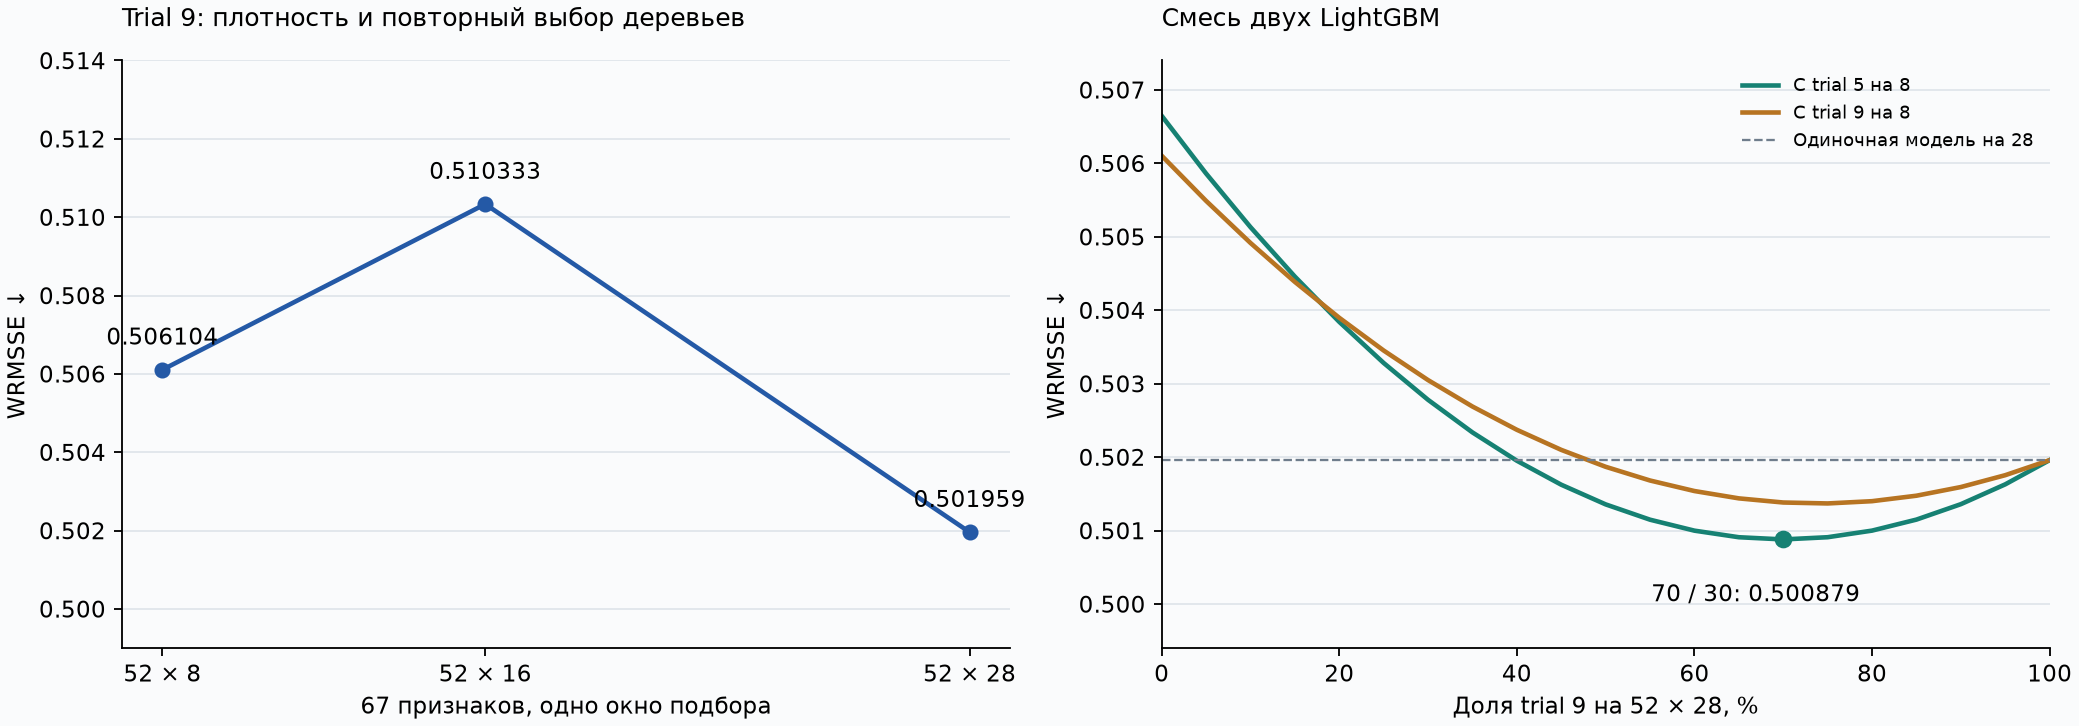

График построен по сохранённым таблицам. Точка 52 × 16 взята со скриншота; остальные значения — из JSON/CSV checkpoint.

## 1. Окружение и повторный запуск

Ноутбук хранит код и выводы завершённых Kaggle-экспериментов. Последний план обучения — одна модель **trial 9 на 52 × 28**. В разделе 8 остаётся вызов fit; выполнение всех ячеек в новой среде может запустить его заново.

Для повторного расчёта **только ансамблей**:

1. Подключить M5 Forecasting — Accuracy и последний `demand-planner_ensemble_three_checkpoint` как Input. Подойдут ZIP и распакованная папка.
2. Выбрать CPU и выполнить разделы **1–3**: окружение, настройки, данные и WRMSSE.
3. Перейти к разделам **10–12**: импорт прогнозов, попарные смеси и тройные смеси. Подготовка признаков и новое обучение для этого не нужны.

В последнем checkpoint уже есть прогнозы всех четырёх моделей, включая CatBoost. Отдельный Output 05 нужен только при использовании более раннего архива без этих прогнозов. При оформлении обновлён только служебный импорт CSV/gzip; эта ячейка очищена и ещё не выполнялась. Остальные сохранённые выводы оставлены от исходного запуска.

In [3]:
from pathlib import Path
import importlib.metadata
import os
import subprocess
import sys

if not Path('/kaggle/input').is_dir():
    raise RuntimeError('Ноутбук предназначен для Kaggle CPU; локальное обучение не запускаем.')
try:
    installed_lightgbm = importlib.metadata.version('lightgbm')
except importlib.metadata.PackageNotFoundError:
    installed_lightgbm = None
if installed_lightgbm != '4.6.0':
    if 'lightgbm' in sys.modules:
        raise RuntimeError('LightGBM другой версии уже импортирован; перезапусти kernel.')
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '--quiet', '--only-binary=:all:', 'lightgbm==4.6.0'],
        check=True,
    )

os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'

from contextlib import redirect_stdout
from datetime import datetime, timezone
from functools import lru_cache
from time import perf_counter
from zipfile import ZIP_DEFLATED, ZipFile, is_zipfile
import fcntl
import gc
import hashlib
import io
import json
import platform
import shutil

import lightgbm as lgb
import numpy as np
import pandas as pd
import scipy
from IPython.display import FileLink, display

pd.set_option('compute.use_bottleneck', False)
pd.set_option('display.max_columns', 30)
print('LightGBM:', lgb.__version__, '| CPU | Bottleneck:', pd.get_option('compute.use_bottleneck'))


LightGBM: 4.6.0 | CPU | Bottleneck: False


## 2. Параметры экспериментов

В экспортированной конфигурации включена плотность **52 × 28**, выбран только **trial 9**. Гиперпараметры взяты из завершённой Optuna на 52 × 8. На новой плотности число деревьев выбиралось заново: максимум 1600, остановка после 200 итераций без улучшения WRMSSE.

`VALIDATION_VARIANTS` хранит настройки уже выполненных проверок на плотности 8. В текущем экспорте задача в разделе 6 создаётся напрямую через `make_tuning_job(28, "trial_009")`; одни переключатели эту явную задачу не меняют.

In [4]:
RUN_DENSITY_16 = False
RUN_OTHER_WINDOWS = False
RUN_DENSITY_28 = True
RESUME_FROM = None

RUN_NAME = "lgbm_finalists_density_v1"
N_ORIGINS = 52
HORIZON = 28
HORIZONS_PER_ORIGIN = 28
NUM_THREADS = 4

TUNING_ORIGIN = pd.Timestamp("2016-03-27")
SEARCH_ORIGIN = TUNING_ORIGIN
PUBLIC_ORIGIN = pd.Timestamp("2016-04-24")
cb_public_origin = PUBLIC_ORIGIN

MAX_BOOST_ROUNDS = 1600
EARLY_STOPPING_ROUNDS = 200

DENSITY_16_VARIANTS = ["trial_009", "trial_005"]
DENSITY_28_VARIANTS = ["trial_009"]

VALIDATION_VARIANTS = [
    ("trial_009", 8),
    ("trial_005", 8),
]

VALIDATION_ORIGINS = [
    "2016-01-31",
    "2016-02-28",
]
PROJECT_ROOT = Path('/kaggle/working/demand-planner')
RESULT_DIR = PROJECT_ROOT / 'results/m5_wrmsse' / RUN_NAME
MODEL_DIR = PROJECT_ROOT / 'models' / RUN_NAME
MANIFEST_PATH = RESULT_DIR / 'manifest.json'
CHECKPOINT_PATH = PROJECT_ROOT.parent / 'demand-planner_validation_density_checkpoint.zip'
REQUIRED_FILES = ('calendar.csv', 'sales_train_validation.csv', 'sell_prices.csv')
candidates = sorted({
    path.parent for path in Path('/kaggle/input').rglob('calendar.csv')
    if all((path.parent / name).is_file() for name in REQUIRED_FILES)
})
if len(candidates) != 1:
    raise FileNotFoundError(f'Подключи один полный набор M5 через Input. Найдено: {len(candidates)}.')
DATA_RAW = candidates[0]
if sum(map(bool, [RUN_DENSITY_16, RUN_OTHER_WINDOWS, RUN_DENSITY_28])) > 1:
    raise ValueError('Включи только один этап за запуск.')

FINALISTS = [{'trial': 9,
  'WRMSSE': 0.5061039037388387,
  'Bias': -0.002460696001496121,
  'best_iteration': 321,
  'params': {'objective': 'tweedie',
             'metric': 'None',
             'boosting_type': 'gbdt',
             'device_type': 'cpu',
             'num_threads': 4,
             'seed': 42,
             'deterministic': True,
             'force_col_wise': True,
             'verbosity': -1,
             'max_depth': -1,
             'max_bin': 255,
             'bin_construct_sample_cnt': 200000,
             'feature_pre_filter': False,
             'bagging_freq': 1,
             'min_sum_hessian_in_leaf': 0.001,
             'min_gain_to_split': 0.0,
             'learning_rate': 0.09975125819860657,
             'num_leaves': 63,
             'min_data_in_leaf': 250,
             'lambda_l1': 0.8827248013286972,
             'lambda_l2': 1.740351379791848,
             'feature_fraction': 0.8563973660909573,
             'bagging_fraction': 0.7579657376635576,
             'tweedie_variance_power': 1.1026305531889093},
  'needs_other_windows_and_densities': True},
 {'trial': 5,
  'WRMSSE': 0.5066471330479768,
  'Bias': -0.010438965087630092,
  'best_iteration': 471,
  'params': {'objective': 'tweedie',
             'metric': 'None',
             'boosting_type': 'gbdt',
             'device_type': 'cpu',
             'num_threads': 4,
             'seed': 42,
             'deterministic': True,
             'force_col_wise': True,
             'verbosity': -1,
             'max_depth': -1,
             'max_bin': 255,
             'bin_construct_sample_cnt': 200000,
             'feature_pre_filter': False,
             'bagging_freq': 1,
             'min_sum_hessian_in_leaf': 0.001,
             'min_gain_to_split': 0.0,
             'learning_rate': 0.09579469687333796,
             'num_leaves': 63,
             'min_data_in_leaf': 250,
             'lambda_l1': 1.0682736700049809,
             'lambda_l2': 0.11322701075434688,
             'feature_fraction': 0.997966521134667,
             'bagging_fraction': 0.7128285798547571,
             'tweedie_variance_power': 1.1168250742845671},
  'needs_other_windows_and_densities': True}]

CONTROL_PARAMS = {'objective': 'tweedie',
 'metric': 'None',
 'boosting_type': 'gbdt',
 'device_type': 'cpu',
 'num_threads': 4,
 'seed': 42,
 'deterministic': True,
 'force_col_wise': True,
 'verbosity': -1,
 'max_depth': -1,
 'max_bin': 255,
 'bin_construct_sample_cnt': 200000,
 'feature_pre_filter': False,
 'bagging_freq': 1,
 'min_sum_hessian_in_leaf': 0.001,
 'min_gain_to_split': 0.0,
 'learning_rate': 0.05,
 'num_leaves': 63,
 'min_data_in_leaf': 100,
 'lambda_l1': 0.0,
 'lambda_l2': 1.0,
 'feature_fraction': 0.9,
 'bagging_fraction': 0.8,
 'tweedie_variance_power': 1.5}

BASE_FEATURE_COLUMNS = ['item_id',
 'dept_id',
 'cat_id',
 'store_id',
 'state_id',
 'mean_7d',
 'mean_28d',
 'mean_56d',
 'std_28d',
 'zero_share_28d',
 'trend_7d_28d',
 'weekday_mean_4w',
 'lag_28d',
 'lag_35d',
 'lag_42d',
 'lag_56d',
 'lag_364d',
 'horizon',
 'day_of_week',
 'day_of_month',
 'month',
 'week_of_year',
 'year',
 'snap',
 'has_event',
 'price_last_known',
 'price_observed_this_week',
 'price_change_1w',
 'price_change_4w',
 'price_vs_mean_4w',
 'price_vs_mean_13w',
 'price_vs_max_13w',
 'price_relative_std_13w',
 'price_observed_share_13w',
 'days_since_last_sale',
 'has_never_sold',
 'sale_day_share_7d',
 'sale_day_share_56d',
 'sale_frequency_change_7d_vs_prev21d',
 'mean_positive_sale_28d',
 'mean_positive_sale_56d',
 'positive_sale_cv2_56d',
 'max_daily_sale_28d',
 'store_dept_mean_7d',
 'store_dept_mean_28d',
 'store_dept_mean_56d',
 'store_dept_trend_7d_28d',
 'store_dept_trend_28d_56d',
 'store_dept_cv_28d',
 'store_dept_weekday_mean_4w',
 'store_dept_weekday_factor_4w',
 'item_share_store_dept_28d',
 'item_share_change_7d_28d',
 'other_stores_mean_7d',
 'other_stores_mean_28d',
 'other_stores_mean_56d',
 'other_stores_trend_7d_28d',
 'other_stores_trend_28d_56d',
 'other_stores_cv_28d',
 'other_stores_weekday_mean_4w',
 'other_stores_weekday_factor_4w',
 'own_vs_other_stores_mean_28d',
 'own_vs_other_stores_trend']

TARGET_PRICE_FEATURES = ['price_target_week',
 'price_target_vs_last',
 'price_target_vs_mean_13w',
 'price_target_missing']

CATEGORICAL_FEATURES = ['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']

FEATURE_SOURCE_SHA256 = '7f870b6044f91821bf0a28613ba30cadb0503c25f0f07f1b87aa439a4cbae650'

SOURCE_OPTUNA_CONTRACT_SHA256 = '3d69c6050671e9d93ccf59941384fdd4c4cd8f21b038bcf0187a97e3682c3cd0'

EXPECTED_RAW_SHA256 = {'calendar.csv': 'd12b5914ef03e66649adf5dd9e996e6602251c22b7a6af8f1f7e3aa12f8860f5',
 'sales_train_validation.csv': 'f368e66ed1dbecb48b2cc8fc589bf68b3deddbbb36bf5c88b4d6d0a09b9b6724',
 'sell_prices.csv': '9da3ad1f8b8ccacdbdc70612191dd375ec24a4ac6625c24b75b3bc60b0bed2ef'}

EXPECTED_NUMERIC_VERSIONS = {'lightgbm': '4.6.0', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.3'}

FEATURE_COLUMNS = [*BASE_FEATURE_COLUMNS, *TARGET_PRICE_FEATURES]
FINALISTS_BY_NAME = {f"trial_{finalist['trial']:03d}": finalist for finalist in FINALISTS}
if len(FEATURE_COLUMNS) != 67 or len(set(FEATURE_COLUMNS)) != 67:
    raise ValueError('Ожидаются 67 уникальных принятых признаков.')
print('Данные:', DATA_RAW)
print('Этапы:', {'52x16': RUN_DENSITY_16, 'other_windows': RUN_OTHER_WINDOWS, '52x28': RUN_DENSITY_28})


Данные: /kaggle/input/competitions/m5-forecasting-accuracy
Этапы: {'52x16': False, 'other_windows': False, '52x28': True}


## 3. Данные и метрика

Используем 30 490 рядов «товар — магазин» и WRMSSE по 12 уровням M5. Масштабы и денежные веса рассчитываются на истории до даты прогноза. Факты следующих 28 дней нужны только для оценки.

Проверяем те же CSV и версии численных библиотек, что в завершённой Optuna. `sales_train_evaluation.csv` и итоговый период июня в этом ноутбуке не читаются.

In [5]:
calendar = pd.read_csv(DATA_RAW / 'calendar.csv', parse_dates=['date'])
if calendar['date'].duplicated().any() or calendar['d'].duplicated().any():
    raise ValueError('В календаре есть повторяющиеся дни.')


In [6]:
identifier_columns = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

series_metadata = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=identifier_columns,
    dtype="string",
)

assert not series_metadata.duplicated(["item_id", "store_id"]).any()
assert len(series_metadata) == 30_490
assert series_metadata["store_id"].nunique() == 10

M5_LEVELS = {
    "Total": [],
    "State": ["state_id"],
    "Store": ["store_id"],
    "Category": ["cat_id"],
    "Department": ["dept_id"],
    "State / Category": ["state_id", "cat_id"],
    "State / Department": ["state_id", "dept_id"],
    "Store / Category": ["store_id", "cat_id"],
    "Store / Department": ["store_id", "dept_id"],
    "Item": ["item_id"],
    "Item / State": ["item_id", "state_id"],
    "Item / Store": ["item_id", "store_id"],
}

hierarchy = pd.DataFrame(
    [
        {
            "level": level,
            "series": (
                series_metadata.groupby(columns, observed=True).ngroups
                if columns
                else 1
            ),
        }
        for level, columns in M5_LEVELS.items()
    ]
).set_index("level")

assert int(hierarchy["series"].sum()) == 42_840
display(hierarchy)
print(f"Всего оцениваемых рядов: {hierarchy['series'].sum():,}")


,series
level,
Total,1
State,3
Store,10
Category,3
Department,7
State / Category,9
State / Department,21
Store / Category,30
Store / Department,70


Всего оцениваемых рядов: 42,840


In [7]:
M5_KEYS = ["store_id", "item_id"]
TRAIN_END_DAY = 1913

train_day_columns = [f"d_{day}" for day in range(1, TRAIN_END_DAY + 1)]

series_index = pd.MultiIndex.from_frame(series_metadata[M5_KEYS])

train_daily = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=[*M5_KEYS, *train_day_columns],
    dtype={
        "store_id": "string",
        "item_id": "string",
        **{column: "int32" for column in train_day_columns},
    },
)

train_daily = (
    train_daily.set_index(M5_KEYS).reindex(series_index).loc[:, train_day_columns]
)

train_daily.columns = pd.DatetimeIndex(
    calendar.set_index("d").loc[train_day_columns, "date"],
    name="date",
)

weight_dates = train_daily.loc[:, :SEARCH_ORIGIN].columns[-28:]

weight_weeks = calendar.set_index("date").loc[weight_dates, "wm_yr_wk"].unique()

price_parts = []

for chunk in pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    usecols=["store_id", "item_id", "wm_yr_wk", "sell_price"],
    dtype={
        "store_id": "string",
        "item_id": "string",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
    chunksize=200_000,
):
    selected = chunk.loc[chunk["wm_yr_wk"].isin(weight_weeks)]

    if not selected.empty:
        price_parts.append(selected.copy())

prices_for_weights = pd.concat(
    price_parts,
    ignore_index=True,
)

del price_parts

print(f"Рядов: {len(train_daily):,}")
print(f"Дней истории: {train_daily.shape[1]:,}")
print(
    "Период для весов:",
    weight_dates.min().date(),
    "—",
    weight_dates.max().date(),
)


Рядов: 30,490
Дней истории: 1,913
Период для весов: 2016-02-29 — 2016-03-27


In [17]:
from scipy.sparse import csr_matrix


def calculate_rmsse_scale(history_values, aggregation, block_size=128):
    n_groups = aggregation.shape[0]
    n_days = history_values.shape[1]

    first_nonzero = np.full(n_groups, n_days, dtype=np.int32)
    squared_difference_sum = np.zeros(n_groups, dtype=np.float64)
    previous = np.zeros(n_groups, dtype=np.float64)

    for start in range(0, n_days, block_size):
        stop = min(start + block_size, n_days)

        block = np.asarray(
            aggregation @ history_values[:, start:stop],
            dtype=np.float64,
        )

        positive = block > 0
        newly_active = (first_nonzero == n_days) & positive.any(axis=1)

        if newly_active.any():
            first_nonzero[newly_active] = start + positive[newly_active].argmax(axis=1)

        differences = np.empty_like(block)
        differences[:, 0] = block[:, 0] - previous
        differences[:, 1:] = np.diff(block, axis=1)

        positions = np.arange(start, stop)
        exclude = positions[None, :] <= first_nonzero[:, None]
        differences[exclude] = 0.0

        squared_difference_sum += np.einsum(
            "ij,ij->i",
            differences,
            differences,
        )

        previous = block[:, -1].copy()

    difference_count = n_days - first_nonzero - 1

    return np.divide(
        squared_difference_sum,
        difference_count,
        out=np.zeros(n_groups, dtype=np.float64),
        where=difference_count > 0,
    )


class M5WRMSSE:
    def __init__(
        self,
        history,
        metadata,
        calendar,
        prices,
        levels,
        horizon=28,
    ):
        if len(metadata) != 30_490 or len(levels) != 12:
            raise ValueError("Для полного M5 нужны 30 490 рядов и 12 уровней.")

        self.series_index = pd.MultiIndex.from_frame(metadata[M5_KEYS])

        if (
            self.series_index.has_duplicates
            or history.index.has_duplicates
            or len(history) != len(self.series_index)
            or not self.series_index.isin(history.index).all()
        ):
            raise ValueError("Идентификаторы истории и metadata не совпадают.")

        history = history.reindex(self.series_index)

        if history.shape[1] < 28:
            raise ValueError("Для расчёта весов нужны минимум 28 дней.")

        if not isinstance(history.columns, pd.DatetimeIndex):
            raise TypeError("Столбцы истории должны содержать даты.")

        expected_history_dates = pd.date_range(
            history.columns[0],
            periods=history.shape[1],
            freq="D",
        )

        if not history.columns.equals(expected_history_dates):
            raise ValueError("В истории есть пропуски или нарушен порядок дней.")

        history_values = history.to_numpy(copy=False)

        if not np.isfinite(history_values).all() or (history_values < 0).any():
            raise ValueError(
                "История должна содержать конечные неотрицательные продажи."
            )

        self.horizon = horizon
        self.n_levels = len(levels)
        self.forecast_dates = pd.date_range(
            history.columns[-1] + pd.Timedelta(days=1),
            periods=horizon,
            freq="D",
            name="date",
        )

        recent_dates = history.columns[-28:]

        week_codes = (
            calendar.set_index("date").reindex(recent_dates)["wm_yr_wk"].to_numpy()
        )

        if pd.isna(week_codes).any():
            raise ValueError("В календаре отсутствуют даты для расчёта весов.")

        known_prices = prices["sell_price"].dropna().to_numpy()

        if not np.isfinite(known_prices).all() or (known_prices <= 0).any():
            raise ValueError("Известные цены должны быть конечными и положительными.")

        price_table = prices.pivot(
            index=M5_KEYS,
            columns="wm_yr_wk",
            values="sell_price",
        )

        daily_prices = price_table.reindex(
            index=self.series_index,
            columns=week_codes,
        ).to_numpy(dtype=np.float64)

        recent_units = history.iloc[:, -28:].to_numpy(dtype=np.float64)

        missing_price_with_sales = (recent_units > 0) & ~np.isfinite(daily_prices)

        if missing_price_with_sales.any():
            raise ValueError(
                "Есть положительные продажи без цены: веса нельзя посчитать корректно."
            )

        dollar_sales = (recent_units * np.nan_to_num(daily_prices, nan=0.0)).sum(axis=1)

        total_dollar_sales = dollar_sales.sum()

        if total_dollar_sales <= 0:
            raise ValueError("Суммарные денежные продажи равны нулю.")

        metadata = metadata.reset_index(drop=True)

        self.level_specs = {}
        level_rows = []

        for level_name, columns in levels.items():
            if columns:
                group_index = pd.MultiIndex.from_frame(metadata[columns])
                codes, groups = pd.factorize(
                    group_index,
                    sort=True,
                )
                n_groups = len(groups)
            else:
                codes = np.zeros(len(metadata), dtype=np.int32)
                n_groups = 1

            aggregation = csr_matrix(
                (
                    np.ones(len(metadata), dtype=np.float64),
                    (codes, np.arange(len(metadata))),
                ),
                shape=(n_groups, len(metadata)),
            )

            print(f"Масштабы: {level_name} — {n_groups:,} рядов")

            scale = calculate_rmsse_scale(
                history_values,
                aggregation,
            )

            group_dollar_sales = np.asarray(aggregation @ dollar_sales).ravel()

            weights = group_dollar_sales / total_dollar_sales / self.n_levels

            if ((scale <= 0) & (weights > 0)).any():
                raise ValueError(
                    f"{level_name}: есть ряд с положительным весом "
                    "и нулевым масштабом RMSSE."
                )

            self.level_specs[level_name] = {
                "aggregation": aggregation,
                "scale": scale,
                "weights": weights,
            }

            level_rows.append(
                {
                    "level": level_name,
                    "series": n_groups,
                    "weight_sum": weights.sum(),
                }
            )

        self.level_info = pd.DataFrame(level_rows).set_index("level")

        if self.level_info["series"].sum() != 42_840:
            raise ValueError("Получено неверное число рядов иерархии.")

        if not np.isclose(self.level_info["weight_sum"].sum(), 1.0):
            raise ValueError("Сумма весов WRMSSE отличается от единицы.")

    def _aligned_values(self, frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("Передай DataFrame с идентификаторами и датами.")

        if (
            frame.index.has_duplicates
            or len(frame) != len(self.series_index)
            or not self.series_index.isin(frame.index).all()
        ):
            raise ValueError("Набор товаров и магазинов не совпадает.")

        if not frame.columns.equals(self.forecast_dates):
            raise ValueError(
                "Столбцы должны содержать следующие 28 дат " "в правильном порядке."
            )

        values = frame.reindex(self.series_index).to_numpy(dtype=np.float64)

        if not np.isfinite(values).all():
            raise ValueError("В фактах или прогнозах есть NaN либо бесконечность.")

        return values

    def score(self, actual, prediction):
        actual_values = self._aligned_values(actual)
        prediction_values = self._aligned_values(prediction)

        bottom_errors = prediction_values - actual_values
        rows = []

        for level_name, spec in self.level_specs.items():
            aggregated_errors = spec["aggregation"] @ bottom_errors

            mse = np.mean(
                np.square(aggregated_errors),
                axis=1,
            )

            rmsse = np.sqrt(
                np.divide(
                    mse,
                    spec["scale"],
                    out=np.zeros_like(mse),
                    where=spec["scale"] > 0,
                )
            )

            contribution = float(np.dot(spec["weights"], rmsse))

            rows.append(
                {
                    "level": level_name,
                    "weighted_RMSSE": contribution * self.n_levels,
                    "contribution": contribution,
                }
            )

        report = pd.DataFrame(rows).set_index("level")
        overall = float(report["contribution"].sum())

        return overall, report


In [18]:
wrmsse_evaluator = M5WRMSSE(
    history=train_daily.loc[:, :SEARCH_ORIGIN],
    metadata=series_metadata,
    calendar=calendar,
    prices=prices_for_weights,
    levels=M5_LEVELS,
    horizon=HORIZON,
)

display(
    wrmsse_evaluator.level_info.style.format(
        {
            "series": "{:,.0f}",
            "weight_sum": "{:.6f}",
        }
    )
)

print(
    "Всего рядов:",
    f"{wrmsse_evaluator.level_info['series'].sum():,}",
)

print(
    "Сумма весов:",
    f"{wrmsse_evaluator.level_info['weight_sum'].sum():.6f}",
)

print(
    "Даты будущего прогноза:",
    wrmsse_evaluator.forecast_dates.min().date(),
    "—",
    wrmsse_evaluator.forecast_dates.max().date(),
)


Масштабы: Total — 1 рядов
Масштабы: State — 3 рядов
Масштабы: Store — 10 рядов
Масштабы: Category — 3 рядов
Масштабы: Department — 7 рядов
Масштабы: State / Category — 9 рядов
Масштабы: State / Department — 21 рядов
Масштабы: Store / Category — 30 рядов
Масштабы: Store / Department — 70 рядов
Масштабы: Item — 3,049 рядов
Масштабы: Item / State — 9,147 рядов
Масштабы: Item / Store — 30,490 рядов


,series,weight_sum
level,,
Total,1,0.083333
State,3,0.083333
Store,10,0.083333
Category,3,0.083333
Department,7,0.083333
State / Category,9,0.083333
State / Department,21,0.083333
Store / Category,30,0.083333
Store / Department,70,0.083333


Всего рядов: 42,840
Сумма весов: 1.000000
Даты будущего прогноза: 2016-03-28 — 2016-04-24


In [19]:
def price_evaluate(evaluator, actual, prediction):
    score, report = evaluator.score(actual, prediction)
    actual_total = (
        actual.reindex(index=prediction.index, columns=prediction.columns)
        .to_numpy(dtype=np.float64)
        .sum()
    )
    metrics = {
        "WRMSSE": float(score),
        "Bias": float(prediction.to_numpy().sum() / actual_total - 1),
    }
    return (metrics, report)


## 4. Признаки и план дат

Оставили **67 признаков**: историю продаж и цены, календарь, регулярность продаж, динамику отдела, продажи того же товара в других магазинах и цену целевой недели. Последние четыре признака используют ценовой план M5. EWMA и короткие лаги в этот набор не входят.

52 — число еженедельных дат отсчёта. Вторая величина — сколько горизонтов из следующих 28 дней берём для каждой даты. Планы вложены: 52 × 8 → 16 → 28. В каждом горизонте присутствуют все 30 490 рядов; обучающие цели заканчиваются до даты проверочного окна.

### Продажи и календарь

Средние и разброс продаж, доля нулей, недельный профиль, лаги от 28 дней и известные календарные признаки. История заканчивается на дате прогноза.

In [20]:
daily_categorical_features = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
]

daily_history = train_daily.reindex(wrmsse_evaluator.series_index)

daily_history_dates = daily_history.columns
daily_history_values = daily_history.to_numpy(copy=False)

daily_identifiers = (
    series_metadata.set_index(M5_KEYS)
    .loc[wrmsse_evaluator.series_index]
    .reset_index()
    .loc[:, daily_categorical_features]
)

daily_identifiers.index = wrmsse_evaluator.series_index

for column in daily_categorical_features:
    daily_identifiers[column] = daily_identifiers[column].astype("category")

daily_calendar = calendar.set_index("date")


def make_daily_features(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)

    horizon = (target_date - forecast_origin).days

    if not 1 <= horizon <= HORIZON:
        raise ValueError("Горизонт должен быть от 1 до 28 дней.")

    origin_position = daily_history_dates.get_indexer([forecast_origin])[0]

    if origin_position < 55:
        raise ValueError(
            "Дата прогноза должна присутствовать в истории "
            "и иметь минимум 56 доступных дней."
        )

    X = daily_identifiers.copy()
    known_history = daily_history_values[:, : origin_position + 1]

    for window in (7, 28, 56):
        X[f"mean_{window}d"] = known_history[:, -window:].mean(axis=1).astype("float32")

    recent_28 = known_history[:, -28:]

    X["std_28d"] = recent_28.std(axis=1, ddof=1).astype("float32")

    X["zero_share_28d"] = (recent_28 == 0).mean(axis=1).astype("float32")

    X["trend_7d_28d"] = (X["mean_7d"] - X["mean_28d"]).astype("float32")

    recent_dates = daily_history_dates[origin_position - 27 : origin_position + 1]

    weekday_mask = recent_dates.dayofweek == target_date.dayofweek

    X["weekday_mean_4w"] = recent_28[:, weekday_mask].mean(axis=1).astype("float32")

    for lag in (28, 35, 42, 56, 364):
        source_date = target_date - pd.Timedelta(days=lag)

        if source_date > forecast_origin:
            raise ValueError("Лаг обращается к неизвестному будущему.")

        source_position = daily_history_dates.get_indexer([source_date])[0]

        if source_position >= 0:
            X[f"lag_{lag}d"] = daily_history_values[:, source_position].astype(
                "float32"
            )
        else:
            X[f"lag_{lag}d"] = np.float32(np.nan)

    calendar_values = daily_calendar.loc[target_date]

    target_features = {
        "horizon": horizon,
        "day_of_week": target_date.dayofweek,
        "day_of_month": target_date.day,
        "month": target_date.month,
        "week_of_year": int(target_date.isocalendar().week),
        "year": target_date.year,
    }

    for name, value in target_features.items():
        X[name] = np.int16(value)

    snap_by_state = {
        state: int(calendar_values[f"snap_{state}"]) for state in ("CA", "TX", "WI")
    }

    X["snap"] = X["state_id"].map(snap_by_state).astype("int8")

    X["has_event"] = np.int8(
        pd.notna(calendar_values["event_name_1"])
        or pd.notna(calendar_values["event_name_2"])
    )

    return X


### История цены

Последняя известная цена, её изменения и положение относительно прошлой истории. Bottleneck выключен до расчёта признаков для сопоставимости с Optuna.

In [21]:
price_data = pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
)
price_week_starts = calendar.groupby("wm_yr_wk")["date"].min().sort_values()
price_week_order = price_week_starts.loc[price_week_starts <= cb_public_origin].index
price_data = price_data.loc[price_data["wm_yr_wk"].isin(price_week_order)].copy()
price_week_table = (
    price_data.pivot(index=M5_KEYS, columns="wm_yr_wk", values="sell_price")
    .reindex(index=wrmsse_evaluator.series_index, columns=price_week_order)
    .astype("float32")
)
price_last_known_table = price_week_table.ffill(axis=1)


@lru_cache(maxsize=64)
def price_features_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    week = int(daily_calendar.loc[forecast_origin, "wm_yr_wk"])
    position = price_week_table.columns.get_loc(week)
    if position < 12:
        raise ValueError("Для признаков цены нужны 13 недель истории.")
    recent_4 = price_week_table.iloc[:, position - 3 : position + 1]
    recent_13 = price_week_table.iloc[:, position - 12 : position + 1]
    current = price_last_known_table.iloc[:, position]
    previous_1 = price_last_known_table.iloc[:, position - 1]
    previous_4 = price_last_known_table.iloc[:, position - 4]
    mean_4 = recent_4.mean(axis=1)
    mean_13 = recent_13.mean(axis=1)
    return pd.DataFrame(
        {
            "price_last_known": current,
            "price_observed_this_week": price_week_table.iloc[:, position].notna(),
            "price_change_1w": current / previous_1 - 1,
            "price_change_4w": current / previous_4 - 1,
            "price_vs_mean_4w": current / mean_4 - 1,
            "price_vs_mean_13w": current / mean_13 - 1,
            "price_vs_max_13w": current / recent_13.max(axis=1) - 1,
            "price_relative_std_13w": recent_13.std(axis=1, ddof=0) / mean_13,
            "price_observed_share_13w": recent_13.notna().mean(axis=1),
        }
    ).astype("float32")


def make_daily_features_with_price(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    base = make_daily_features(forecast_origin=forecast_origin, target_date=target_date)
    return base.join(price_features_at_origin(forecast_origin), validate="one_to_one")


### Регулярность продаж

Как давно товар покупали, как часто продажи были положительными и насколько менялся размер покупки. Это помогает различать устойчивые продажи и редкий спрос.

In [24]:
@lru_cache(maxsize=64)
def regularity_features_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    position = daily_history_dates.get_indexer([forecast_origin])[0]
    if position < 55:
        raise ValueError(
            "Дата должна присутствовать в истории и иметь минимум 56 доступных дней."
        )
    known = daily_history_values[:, : position + 1]
    positive_history = known > 0
    has_ever_sold = positive_history.any(axis=1)
    days_since_sale = positive_history[:, ::-1].argmax(axis=1).astype("float32")
    days_since_sale[~has_ever_sold] = np.nan
    recent_56 = known[:, -56:].astype("float64")
    recent_28 = recent_56[:, -28:]
    positive_56 = positive_history[:, -56:]
    positive_28 = positive_56[:, -28:]
    count_56 = positive_56.sum(axis=1)
    count_28 = positive_28.sum(axis=1)
    sum_56 = recent_56.sum(axis=1)
    sum_28 = recent_28.sum(axis=1)
    mean_positive_56 = np.divide(
        sum_56, count_56, out=np.full(len(known), np.nan), where=count_56 > 0
    )
    mean_positive_28 = np.divide(
        sum_28, count_28, out=np.full(len(known), np.nan), where=count_28 > 0
    )
    squared_sum_56 = np.einsum("ij,ij->i", recent_56, recent_56)
    correction = np.divide(
        np.square(sum_56), count_56, out=np.zeros(len(known)), where=count_56 > 0
    )
    positive_variance_56 = np.divide(
        np.maximum(squared_sum_56 - correction, 0.0),
        count_56 - 1,
        out=np.full(len(known), np.nan),
        where=count_56 > 1,
    )
    positive_cv2_56 = np.divide(
        positive_variance_56,
        np.square(mean_positive_56),
        out=np.full(len(known), np.nan),
        where=count_56 > 1,
    )
    frequency_7 = positive_56[:, -7:].mean(axis=1)
    frequency_previous_21 = positive_56[:, -28:-7].mean(axis=1)
    return pd.DataFrame(
        {
            "days_since_last_sale": days_since_sale,
            "has_never_sold": ~has_ever_sold,
            "sale_day_share_7d": frequency_7,
            "sale_day_share_56d": positive_56.mean(axis=1),
            "sale_frequency_change_7d_vs_prev21d": frequency_7 - frequency_previous_21,
            "mean_positive_sale_28d": mean_positive_28,
            "mean_positive_sale_56d": mean_positive_56,
            "positive_sale_cv2_56d": positive_cv2_56,
            "max_daily_sale_28d": recent_28.max(axis=1),
        },
        index=wrmsse_evaluator.series_index,
    ).astype("float32")


def make_daily_features_with_regularity(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    X = make_daily_features_with_price(forecast_origin, target_date)
    return X.join(regularity_features_at_origin(forecast_origin), validate="one_to_one")


### Отдел в магазине

Общая динамика отдела, его недельный профиль и доля товара в продажах. Групповые значения используют только доступную историю.

In [25]:
group_aggregation = wrmsse_evaluator.level_specs["Store / Department"]["aggregation"]
group_membership = group_aggregation.tocoo()
group_codes = np.empty(len(wrmsse_evaluator.series_index), dtype=np.int32)
group_codes[group_membership.col] = group_membership.row
group_daily_sales = np.asarray(
    group_aggregation @ daily_history_values, dtype=np.float64
)


def group_safe_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=np.float64)
    denominator = np.asarray(denominator, dtype=np.float64)
    return np.divide(
        numerator,
        denominator,
        out=np.full(numerator.shape, np.nan),
        where=denominator > 0,
    )


@lru_cache(maxsize=64)
def group_statistics_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    position = daily_history_dates.get_indexer([forecast_origin])[0]
    if position < 55:
        raise ValueError("Для групповых признаков нужны 56 доступных дней.")
    known = group_daily_sales[:, : position + 1]
    recent_28 = known[:, -28:]
    recent_dates = daily_history_dates[position - 27 : position + 1]
    statistics = {
        f"mean_{window}d": known[:, -window:].mean(axis=1) for window in (7, 28, 56)
    }
    statistics["std_28d"] = recent_28.std(axis=1, ddof=1)
    statistics["weekday_mean_4w"] = np.column_stack(
        [
            recent_28[:, recent_dates.dayofweek == weekday].mean(axis=1)
            for weekday in range(7)
        ]
    )
    return statistics


def make_daily_features_with_groups(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)
    X = make_daily_features_with_regularity(forecast_origin, target_date)
    statistics = group_statistics_at_origin(forecast_origin)
    mean_7 = statistics["mean_7d"][group_codes]
    mean_28 = statistics["mean_28d"][group_codes]
    mean_56 = statistics["mean_56d"][group_codes]
    weekday_mean = statistics["weekday_mean_4w"][group_codes, target_date.dayofweek]
    item_share_7 = group_safe_ratio(X["mean_7d"].to_numpy(), mean_7)
    item_share_28 = group_safe_ratio(X["mean_28d"].to_numpy(), mean_28)
    added_features = {
        "store_dept_mean_7d": mean_7,
        "store_dept_mean_28d": mean_28,
        "store_dept_mean_56d": mean_56,
        "store_dept_trend_7d_28d": group_safe_ratio(mean_7, mean_28) - 1,
        "store_dept_trend_28d_56d": group_safe_ratio(mean_28, mean_56) - 1,
        "store_dept_cv_28d": group_safe_ratio(
            statistics["std_28d"][group_codes], mean_28
        ),
        "store_dept_weekday_mean_4w": weekday_mean,
        "store_dept_weekday_factor_4w": group_safe_ratio(weekday_mean, mean_28),
        "item_share_store_dept_28d": item_share_28,
        "item_share_change_7d_28d": item_share_7 - item_share_28,
    }
    for column, values in added_features.items():
        X[column] = values.astype("float32")
    return X


### Тот же товар в других магазинах

Считаем динамику товара по остальным магазинам, исключая текущий. Сравниваем общий и локальный уровень продаж.

In [26]:
cross_store_aggregation = wrmsse_evaluator.level_specs["Item"]["aggregation"]
cross_store_membership = cross_store_aggregation.tocoo()
cross_store_codes = np.empty(len(wrmsse_evaluator.series_index), dtype=np.int32)
cross_store_codes[cross_store_membership.col] = cross_store_membership.row
cross_store_counts = np.asarray(cross_store_aggregation.sum(axis=1)).ravel()
cross_store_other_counts = cross_store_counts[cross_store_codes] - 1
cross_store_daily_totals = np.asarray(
    cross_store_aggregation @ daily_history_values, dtype=np.float64
)


@lru_cache(maxsize=64)
def cross_store_statistics_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    position = daily_history_dates.get_indexer([forecast_origin])[0]
    if position < 55:
        raise ValueError("Для признаков других магазинов нужны 56 дней истории.")
    start = position - 55
    network_sales = cross_store_daily_totals[cross_store_codes, start : position + 1]
    own_sales = daily_history_values[:, start : position + 1]
    other_sales = (network_sales - own_sales) / cross_store_other_counts[:, None]
    recent_28 = other_sales[:, -28:]
    recent_dates = daily_history_dates[position - 27 : position + 1]
    statistics = {
        f"mean_{window}d": other_sales[:, -window:].mean(axis=1).astype("float32")
        for window in (7, 28, 56)
    }
    statistics["std_28d"] = recent_28.std(axis=1, ddof=1).astype("float32")
    statistics["weekday_mean_4w"] = np.column_stack(
        [
            recent_28[:, recent_dates.dayofweek == weekday].mean(axis=1)
            for weekday in range(7)
        ]
    ).astype("float32")
    return statistics


def make_daily_features_with_cross_store(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)
    X = make_daily_features_with_groups(forecast_origin, target_date)
    statistics = cross_store_statistics_at_origin(forecast_origin)
    mean_7 = statistics["mean_7d"]
    mean_28 = statistics["mean_28d"]
    mean_56 = statistics["mean_56d"]
    weekday_mean = statistics["weekday_mean_4w"][:, target_date.dayofweek]
    own_trend = group_safe_ratio(X["mean_7d"].to_numpy(), X["mean_28d"].to_numpy()) - 1
    other_trend = group_safe_ratio(mean_7, mean_28) - 1
    added_features = {
        "other_stores_mean_7d": mean_7,
        "other_stores_mean_28d": mean_28,
        "other_stores_mean_56d": mean_56,
        "other_stores_trend_7d_28d": other_trend,
        "other_stores_trend_28d_56d": group_safe_ratio(mean_28, mean_56) - 1,
        "other_stores_cv_28d": group_safe_ratio(statistics["std_28d"], mean_28),
        "other_stores_weekday_mean_4w": weekday_mean,
        "other_stores_weekday_factor_4w": group_safe_ratio(weekday_mean, mean_28),
        "own_vs_other_stores_mean_28d": group_safe_ratio(
            X["mean_28d"].to_numpy(), mean_28
        ),
        "own_vs_other_stores_trend": own_trend - other_trend,
    }
    for column, values in added_features.items():
        X[column] = values.astype("float32")
    return X


### Цена целевой недели и сборка выборки

Добавляем четыре ценовых признака. Категории train и validation согласованы. Справочная строка старой проверки ниже показывает объём **52 × 16**; фактическая плотность текущего запуска задаётся в разделе 6.

In [27]:
CATEGORY_TYPES = {
    column: pd.CategoricalDtype(
        categories=daily_identifiers[column].cat.categories,
        ordered=False,
    )
    for column in CATEGORICAL_FEATURES
}

target_price_source = pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    usecols=["store_id", "item_id", "wm_yr_wk", "sell_price"],
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float32",
    },
)
observed_prices = target_price_source["sell_price"].dropna().to_numpy()
if not np.isfinite(observed_prices).all() or (observed_prices <= 0).any():
    raise ValueError("Некорректные наблюдаемые цены.")
target_week_prices = (
    target_price_source.pivot(
        index=M5_KEYS, columns="wm_yr_wk", values="sell_price"
    )
    .reindex(index=wrmsse_evaluator.series_index)
    .astype("float32")
)
del target_price_source, observed_prices
gc.collect()


def prepare_categories(frame):
    for column, dtype in CATEGORY_TYPES.items():
        frame[column] = frame[column].astype(dtype)
        if frame[column].isna().any():
            raise ValueError(f"Неизвестная категория в {column}.")
    return frame


def relative_price_change(numerator, denominator):
    result = np.full(len(numerator), np.nan, dtype=np.float32)
    valid = (
        np.isfinite(numerator)
        & np.isfinite(denominator)
        & (denominator > 0)
    )
    np.divide(numerator, denominator, out=result, where=valid)
    return result - np.float32(1)


@lru_cache(maxsize=64)
def historical_price_mean_13w(forecast_origin):
    week = int(daily_calendar.loc[forecast_origin, "wm_yr_wk"])
    position = price_week_table.columns.get_loc(week)
    if position < 12:
        raise ValueError("Для среднего цены нужны 13 недель истории.")
    return (
        price_week_table.iloc[:, position - 12 : position + 1]
        .mean(axis=1)
        .to_numpy(dtype=np.float32)
    )


def make_daily_features_final(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)
    frame = make_daily_features_with_cross_store(forecast_origin, target_date)
    if (
        frame.columns.tolist() != BASE_FEATURE_COLUMNS
        or not frame.index.equals(wrmsse_evaluator.series_index)
    ):
        raise ValueError("Изменились базовые признаки или порядок рядов.")
    target_week = int(daily_calendar.loc[target_date, "wm_yr_wk"])
    target_price = target_week_prices[target_week].to_numpy()
    last_price = frame["price_last_known"].to_numpy()
    frame["price_target_week"] = target_price
    frame["price_target_vs_last"] = relative_price_change(target_price, last_price)
    frame["price_target_vs_mean_13w"] = relative_price_change(
        target_price, historical_price_mean_13w(forecast_origin)
    )
    frame["price_target_missing"] = (~np.isfinite(target_price)).astype("float32")
    return prepare_categories(frame.loc[:, FEATURE_COLUMNS])


In [30]:
def make_training_plan(label_cutoff, horizons_per_origin=16):
    if horizons_per_origin not in (2, 4, 8, 16, 28):
        raise ValueError("Допустимы планы 52 × 2, 4, 8, 16 или 28.")
    label_cutoff = pd.Timestamp(label_cutoff)
    origins = pd.date_range(
        end=label_cutoff - pd.Timedelta(days=HORIZON),
        periods=N_ORIGINS,
        freq="7D",
    )
    rows = []
    for number, origin in enumerate(origins):
        first = 5 * number % HORIZON + 1
        old = {first, (5 * number + HORIZON // 2) % HORIZON + 1}
        if number == N_ORIGINS - 1:
            old = {1, HORIZON}
        four = old | (
            {10, 19}
            if number == N_ORIGINS - 1
            else {(first - 1 + shift) % HORIZON + 1 for shift in (7, 21)}
        )
        eight = four | (
            {5, 14, 23, 26}
            if number == N_ORIGINS - 1
            else {
                (first - 1 + shift) % HORIZON + 1
                for shift in (3, 10, 17, 24)
            }
        )
        if len(old) != 2 or len(four) != 4 or len(eight) != 8:
            raise ValueError("Изменился исходный план горизонтов.")
        horizons = set({2: old, 4: four}.get(horizons_per_origin, eight))
        while len(horizons) < horizons_per_origin:
            candidates = set(range(1, HORIZON + 1)) - horizons

            def separation(candidate):
                return min(
                    min(abs(candidate - old), HORIZON - abs(candidate - old))
                    for old in horizons
                )

            selected = max(
                candidates,
                key=lambda candidate: (separation(candidate), -candidate),
            )
            horizons.add(selected)
        for horizon in sorted(horizons):
            target_date = origin + pd.Timedelta(days=horizon)
            if target_date > label_cutoff:
                raise ValueError("Цель выходит за конец обучающей истории.")
            rows.append(
                {
                    "origin": origin,
                    "horizon": horizon,
                    "target_date": target_date,
                    "present_in_52x2": horizon in old,
                    "present_in_52x4": horizon in four,
                    "present_in_52x8": horizon in eight,
                }
            )
    return pd.DataFrame(rows)


def clear_feature_caches():
    for function in (
        price_features_at_origin,
        regularity_features_at_origin,
        group_statistics_at_origin,
        cross_store_statistics_at_origin,
        historical_price_mean_13w,
    ):
        function.cache_clear()
    gc.collect()


def build_feature_dataset(pairs, label_cutoff=None):
    pairs = list(pairs)
    if not pairs:
        raise ValueError("Пустой план подготовки данных.")
    n_series = len(wrmsse_evaluator.series_index)
    n_rows = len(pairs) * n_series
    storage = None
    y = np.empty(n_rows, dtype=np.float32) if label_cutoff is not None else None
    if label_cutoff is not None:
        label_cutoff = pd.Timestamp(label_cutoff)
    for number, (origin, target_date) in enumerate(pairs, start=1):
        origin = pd.Timestamp(origin)
        target_date = pd.Timestamp(target_date)
        frame = make_daily_features_final(origin, target_date)
        if storage is None:
            storage = {
                column: np.empty(
                    n_rows,
                    dtype=(
                        frame[column].cat.codes.dtype
                        if column in CATEGORICAL_FEATURES
                        else frame[column].dtype
                    ),
                )
                for column in FEATURE_COLUMNS
            }
        start = (number - 1) * n_series
        stop = start + n_series
        for column in FEATURE_COLUMNS:
            values = (
                frame[column].cat.codes.to_numpy()
                if column in CATEGORICAL_FEATURES
                else frame[column].to_numpy()
            )
            storage[column][start:stop] = values
        if y is not None:
            position = daily_history_dates.get_indexer([target_date])[0]
            if (
                position < 0
                or target_date > label_cutoff
                or origin >= target_date
                or origin > label_cutoff
            ):
                raise ValueError("Недоступная дата обучающей цели.")
            y[start:stop] = daily_history_values[:, position]
            if number % (HORIZONS_PER_ORIGIN * 13) == 0:
                print(
                    f"Подготовлено дат: {number // HORIZONS_PER_ORIGIN}/52",
                    flush=True,
                )
    if y is not None and (not np.isfinite(y).all() or (y < 0).any()):
        raise ValueError("Некорректные целевые продажи.")
    data = {
        column: (
            pd.Categorical.from_codes(storage[column], dtype=CATEGORY_TYPES[column])
            if column in CATEGORICAL_FEATURES
            else storage[column]
        )
        for column in FEATURE_COLUMNS
    }
    return pd.DataFrame(data, columns=FEATURE_COLUMNS, copy=False), y


def make_window_evaluator(origin):
    history = daily_history.loc[:, :origin]
    weeks = daily_calendar.loc[history.columns[-28:], "wm_yr_wk"].unique()
    with redirect_stdout(io.StringIO()):
        evaluator = M5WRMSSE(
            history=history,
            metadata=series_metadata,
            calendar=calendar,
            prices=price_data.loc[price_data["wm_yr_wk"].isin(weeks)],
            levels=M5_LEVELS,
            horizon=HORIZON,
        )
    return evaluator


def prediction_frame(model, frame, evaluator):
    values = model.predict(frame)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Некорректные значения прогноза.")
    return pd.DataFrame(
        values.reshape(HORIZON, len(evaluator.series_index)).T,
        index=evaluator.series_index,
        columns=evaluator.forecast_dates,
    )


In [31]:
if pd.get_option('compute.use_bottleneck'):
    raise RuntimeError('Bottleneck должен быть отключён до расчёта признаков.')
if TUNING_ORIGIN + pd.Timedelta(days=HORIZON) > daily_history_dates[-1]:
    raise ValueError('Не хватает фактов окна подбора.')
for horizon in (1, HORIZON):
    probe = make_daily_features_final(TUNING_ORIGIN, TUNING_ORIGIN + pd.Timedelta(days=horizon))
    if probe.columns.tolist() != FEATURE_COLUMNS or not probe.index.equals(wrmsse_evaluator.series_index):
        raise ValueError('Изменились признаки или порядок рядов.')
    if np.isinf(probe.select_dtypes(include='number').to_numpy()).any():
        raise ValueError('В признаках есть бесконечные значения.')
print('Признаков:', len(FEATURE_COLUMNS))
print('Строк на 52 × 16:', f'{N_ORIGINS * 16 * len(probe):,}')
del probe
clear_feature_caches()


Признаков: 67
Строк на 52 × 16: 25,367,680


## 5. Протокол и checkpoint

Сохраняем версии, хеши исходных CSV, состав признаков и параметры. У каждого обучения есть отдельный протокол и хеши созданных файлов. Записанный протокол связывает метрику с конкретной моделью и прогнозом.

Модель и полные прогнозы остаются локально. В Git идут ноутбук, небольшие таблицы, протоколы и график. При переносе gzip через Kaggle сжатый файл может превратиться в CSV; импорт прогнозов для ансамбля вынесен в раздел 10.

In [33]:
def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )
    temporary.replace(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as source:
        for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def json_digest(value):
    text = json.dumps(value, ensure_ascii=False, sort_keys=True, allow_nan=False)
    return hashlib.sha256(text.encode()).hexdigest()

def atomic_csv(path, frame, index=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    frame.to_csv(temporary, index=index, date_format='%Y-%m-%d')
    temporary.replace(path)

def restore_checkpoint(source):
    source = Path(source)
    prefixes = [Path('results/m5_wrmsse') / RUN_NAME, Path('models') / RUN_NAME]
    manifest_relative = prefixes[0] / 'manifest.json'
    if MANIFEST_PATH.exists():
        raise FileExistsError('В рабочей папке уже есть история ноутбука 06.')
    if source.is_file():
        if not is_zipfile(source):
            raise ValueError('Для восстановления нужен ZIP или распакованная папка.')
        with ZipFile(source) as archive:
            files = [info for info in archive.infolist() if not info.is_dir()]
            if str(manifest_relative) not in {info.filename for info in files}:
                raise ValueError('Это checkpoint другой работы; нужен архив ноутбука 06.')
            safe_files = []
            for info in files:
                relative = Path(info.filename)
                if relative.is_absolute() or '..' in relative.parts:
                    raise ValueError('Некорректный путь в checkpoint.')
                if not any(relative.is_relative_to(prefix) for prefix in prefixes):
                    raise ValueError(f'Лишний путь в checkpoint: {relative}')
                if (info.external_attr >> 16) & 0o170000 == 0o120000:
                    raise ValueError('Ссылки в checkpoint не поддерживаются.')
                safe_files.append((info, relative))
            for info, relative in safe_files:
                target = PROJECT_ROOT / relative
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(info) as incoming, target.open('wb') as outgoing:
                    shutil.copyfileobj(incoming, outgoing)
    elif source.is_dir():
        if not (source / manifest_relative).is_file():
            raise ValueError('Нужна папка, внутри которой лежат results/ и models/ ноутбука 06.')
        for prefix in prefixes:
            for incoming in sorted((source / prefix).rglob('*')):
                if incoming.is_symlink():
                    raise ValueError('Ссылки в checkpoint не поддерживаются.')
                if incoming.is_file():
                    target = PROJECT_ROOT / incoming.relative_to(source)
                    target.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(incoming, target)
    else:
        raise FileNotFoundError(source)
    print('Восстановлен checkpoint:', source)

def prepare_workspace():
    if not MANIFEST_PATH.exists():
        source = RESUME_FROM
        if source is None:
            archives = sorted(Path('/kaggle/input').rglob(CHECKPOINT_PATH.name))
            suffix = Path('results/m5_wrmsse') / RUN_NAME / 'manifest.json'
            folders = sorted({
                path.parents[3] for path in Path('/kaggle/input').rglob('manifest.json')
                if path.as_posix().endswith(suffix.as_posix())
            })
            candidates = archives if archives else folders
            if len(candidates) > 1:
                raise ValueError('Найдено несколько checkpoint 06; укажи один в RESUME_FROM.')
            source = candidates[0] if candidates else None
        if source is not None:
            restore_checkpoint(source)
    versions = {
        'python': platform.python_version(), 'lightgbm': lgb.__version__,
        'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
    }
    mismatches = {
        name: {'expected': expected, 'actual': versions[name]}
        for name, expected in EXPECTED_NUMERIC_VERSIONS.items() if versions[name] != expected
    }
    if mismatches:
        raise RuntimeError(
            f'Версии отличаются от выполненного Optuna: {mismatches}. '
            'Для сопоставимой проверки используй ту же среду Kaggle. '
            'Не смешиваем результаты из разных версий в одной истории.'
        )
    print('Сверяю исходные CSV с выполненным Optuna.', flush=True)
    hashes = {name: sha256_file(DATA_RAW / name) for name in REQUIRED_FILES}
    if hashes != EXPECTED_RAW_SHA256:
        raise RuntimeError('Байты исходных CSV отличаются от Optuna. Проверь подключённый M5.')
    if pd.get_option('compute.use_bottleneck'):
        raise RuntimeError('Bottleneck должен быть выключен до подготовки признаков.')
    contract = {
        'schema': 1, 'run_name': RUN_NAME,
        'features': FEATURE_COLUMNS, 'categorical_features': CATEGORICAL_FEATURES,
        'feature_source_sha256': FEATURE_SOURCE_SHA256,
        'raw_sha256': hashes, 'versions': versions,
        'source_optuna_contract_sha256': SOURCE_OPTUNA_CONTRACT_SHA256,
        'source_finalists': FINALISTS, 'control_params': CONTROL_PARAMS,
        'n_origins': N_ORIGINS, 'horizon': HORIZON,
        'tuning_origin': str(TUNING_ORIGIN.date()),
        'max_boost_rounds': MAX_BOOST_ROUNDS,
        'early_stopping_rounds': EARLY_STOPPING_ROUNDS,
        'compute_use_bottleneck': False,
    }
    if MANIFEST_PATH.exists():
        saved = json.loads(MANIFEST_PATH.read_text())
        if saved.get('contract') != contract or saved.get('sha256') != json_digest(contract):
            raise RuntimeError('Изменился протокол 06. Восстанови настройки или задай новый RUN_NAME.')
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    atomic_json(MANIFEST_PATH, {'sha256': json_digest(contract), 'contract': contract})
    atomic_json(RESULT_DIR / 'source_finalists.json', FINALISTS)
    print('Версии:', versions)
    print('Исходные CSV совпадают: True | Признаков:', len(FEATURE_COLUMNS))
    return contract


In [34]:
WORKSPACE_CONTRACT = prepare_workspace()


Сверяю исходные CSV с выполненным Optuna.
Версии: {'python': '3.13.15', 'lightgbm': '4.6.0', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.3'}
Исходные CSV совпадают: True | Признаков: 67


## 6. План последнего обучения

Здесь создана одна задача: **trial 9, 52 × 28**, дата отсчёта **27 марта 2016 года**, early stopping по WRMSSE. Лучший результат получился на **197 деревьях**; проверено 397 итераций.

Ранее для плотности 8 проверили ещё два периода: **1–28 февраля** и **29 февраля — 27 марта**. Число деревьев было фиксировано: контроль — 386, trial 9 — 321, trial 5 — 471.

| Период | Контроль ↓ | Trial 9 ↓ | Trial 5 ↓ |
|---|---:|---:|---:|
| 1–28 февраля | 0.764329 | **0.728815** | 0.752058 |
| 29 февраля — 27 марта | 0.672673 | 0.670937 | **0.665074** |

Оба кандидата выиграли у контроля в двух окнах. Средний относительный выигрыш по показанным окнам: **2.45%** у trial 9 и **1.37%** у trial 5. Числа этой таблицы переписаны со скриншота, полного протокола этих запусков в последнем checkpoint нет. Плотность 28 и смесь 70 / 30 на этих двух окнах пока не проверялись.

In [35]:
def job_name(phase, origin, density, variant):
    return f'{phase}_{pd.Timestamp(origin).date()}_52x{density}_{variant}'

def completed_job(job):
    name = job['name']
    protocol_path = RESULT_DIR / name / 'protocol.json'
    if not protocol_path.exists():
        return None
    protocol = json.loads(protocol_path.read_text())
    if protocol.get('job') != job or protocol.get('job_sha256') != json_digest(job):
        raise RuntimeError(f'Для {name} уже сохранён другой протокол. Не перезаписываем его.')
    if protocol.get('workspace_sha256') != json_digest(WORKSPACE_CONTRACT):
        raise RuntimeError(f'Для {name} изменились данные, признаки или среда.')
    for relative, expected_hash in protocol['artifact_sha256'].items():
        artifact = PROJECT_ROOT / relative
        if not artifact.is_file() or sha256_file(artifact) != expected_hash:
            raise RuntimeError(f'Checkpoint неполный или повреждён: {relative}')
    return protocol

def make_tuning_job(density, variant):
    if variant not in FINALISTS_BY_NAME or density not in (16, 28):
        raise ValueError('Для плотности 16/28 нужны Trial 9 или Trial 5.')
    name = job_name(f'density{density}', TUNING_ORIGIN, density, variant)
    return {
        'name': name, 'phase': f'density{density}', 'origin': str(TUNING_ORIGIN.date()),
        'density': density, 'variant': variant,
        'params': FINALISTS_BY_NAME[variant]['params'],
        'tree_selection': 'early_stopping_on_tuning_window',
        'num_boost_round': MAX_BOOST_ROUNDS,
        'early_stopping_rounds': EARLY_STOPPING_ROUNDS,
        'frozen_from': None,
    }

def frozen_trees(variant, density):
    if variant == 'control':
        return 386, {'source': 'fixed_control', 'trees': 386}
    if variant not in FINALISTS_BY_NAME:
        raise ValueError(f'Неизвестный вариант: {variant}')
    if density == 8:
        return int(FINALISTS_BY_NAME[variant]['best_iteration']), {
            'source': 'completed_optuna_52x8',
            'source_contract_sha256': SOURCE_OPTUNA_CONTRACT_SHA256,
        }
    if density not in (16, 28):
        raise ValueError('Для проверки доступны плотности 8, 16 и 28.')
    tuning = completed_job(make_tuning_job(density, variant))
    if tuning is None:
        raise FileNotFoundError(
            f'Нет результата {variant}, 52 × {density} на окне подбора. '
            'Сначала выполни этот этап и подключи его checkpoint как Input.'
        )
    return int(tuning['best_iteration']), {
        'source': tuning['job']['name'], 'job_sha256': tuning['job_sha256'],
        'trees': int(tuning['best_iteration']),
    }

def make_validation_job(origin, density, variant):
    origin = pd.Timestamp(origin)
    if origin == TUNING_ORIGIN:
        raise ValueError('Окно подбора не используем как дополнительное окно проверки.')
    if density not in (8, 16, 28):
        raise ValueError('Недопустимая плотность проверки.')
    trees, parent = frozen_trees(variant, density)
    params = CONTROL_PARAMS if variant == 'control' else FINALISTS_BY_NAME[variant]['params']
    return {
        'name': job_name('validation', origin, density, variant),
        'phase': 'validation', 'origin': str(origin.date()), 'density': density,
        'variant': variant, 'params': params,
        'tree_selection': 'fixed_before_validation', 'num_boost_round': trees,
        'early_stopping_rounds': None, 'frozen_from': parent,
    }

def validation_jobs():
    if not VALIDATION_VARIANTS or not VALIDATION_ORIGINS:
        raise ValueError('Задай варианты и даты проверки.')
    pairs = [tuple(pair) for pair in VALIDATION_VARIANTS]
    if len(set(pairs)) != len(pairs):
        raise ValueError('Повторяющиеся варианты проверки.')
    if len(set(map(pd.Timestamp, VALIDATION_ORIGINS))) != len(VALIDATION_ORIGINS):
        raise ValueError('Повторяющиеся даты проверки.')
    jobs = []
    for origin in VALIDATION_ORIGINS:
        for density in sorted({density for _, density in pairs}):
            jobs.append(make_validation_job(origin, density, 'control'))
            jobs.extend(make_validation_job(origin, density, variant)
                        for variant, candidate_density in pairs if candidate_density == density)
    return jobs

def check_validation_before_28():
    if not VALIDATION_ORIGINS or not DENSITY_28_VARIANTS:
        raise ValueError('Для 52 × 28 нужны выбранные финалисты и непустой список окон проверки.')
    for variant in DENSITY_28_VARIANTS:
        densities = [density for candidate, density in VALIDATION_VARIANTS
                     if candidate == variant and density in (8, 16)]
        ready = False
        for density in densities:
            if all(
                completed_job(make_validation_job(origin, density, name)) is not None
                for origin in VALIDATION_ORIGINS for name in (variant, 'control')
            ):
                ready = True
                break
        if not ready:
            raise FileNotFoundError(
                f'Для {variant} не завершены проверки и контроль на дополнительных окнах. '
                'Сначала запусти этап проверки, посмотри результаты и подключи его checkpoint.'
            )

def selected_jobs():
    switches = [RUN_DENSITY_16, RUN_OTHER_WINDOWS, RUN_DENSITY_28]
    if sum(map(bool, switches)) > 1:
        raise ValueError('За один запуск включи только один этап.')
    if RUN_DENSITY_16:
        if not DENSITY_16_VARIANTS:
            raise ValueError('Выбери хотя бы одного финалиста для 52 × 16.')
        return [make_tuning_job(16, variant) for variant in DENSITY_16_VARIANTS]
    if RUN_OTHER_WINDOWS:
        return validation_jobs()
    if RUN_DENSITY_28:
        check_validation_before_28()
        return [make_tuning_job(28, variant) for variant in DENSITY_28_VARIANTS]
    return []


In [36]:
JOBS = [
    make_tuning_job(density=28, variant="trial_009")
]

print("Запрошено обучений:", len(JOBS))

display(pd.DataFrame([
    {
        key: job[key]
        for key in (
            "origin",
            "density",
            "variant",
            "tree_selection",
            "num_boost_round",
            "early_stopping_rounds",
        )
    }
    for job in JOBS
]))

Запрошено обучений: 1


,origin,density,variant,tree_selection,num_boost_round,early_stopping_rounds
0,2016-03-27,28,trial_009,early_stopping_on_tuning_window,1600,200


## 7. Подготовка Dataset и обучение

Строим train и бины один раз на сочетание даты и плотности. Для 52 × 28 получилось **44 393 440 строк**, таблица признаков заняла **9.76 GiB**. Подготовка и fit записаны раздельно: около **3.2** и **37.6 минуты** в сохранённом запуске.

На окне подбора используется early stopping. Функции проверки других окон поддерживают заранее фиксированное число деревьев. Быстрый WRMSSE сверяется с обычным расчётом.

In [38]:
def build_fast_wrmsse(evaluator, actual):
    actual_values = evaluator._aligned_values(actual)
    aggregation = scipy.sparse.vstack(
        [spec["aggregation"] for spec in evaluator.level_specs.values()], format="csr"
    )
    scales = np.concatenate([spec["scale"] for spec in evaluator.level_specs.values()])
    weights = np.concatenate([spec["weights"] for spec in evaluator.level_specs.values()])
    factors = np.divide(
        weights,
        np.sqrt(scales),
        out=np.zeros_like(weights),
        where=scales > 0,
    )
    n_series, horizon = actual_values.shape

    def score(prediction):
        prediction = np.asarray(prediction, dtype=np.float64)
        if prediction.shape != (n_series * horizon,) or not np.isfinite(prediction).all():
            raise ValueError("Неверный размер или неконечный прогноз для WRMSSE.")
        errors = prediction.reshape(horizon, n_series).T - actual_values
        aggregated = aggregation @ errors
        rmse = np.sqrt(np.einsum("ij,ij->i", aggregated, aggregated) / horizon)
        return float(np.dot(factors, rmse))

    return score


In [39]:
def build_window_data(origin, density):
    origin = pd.Timestamp(origin)
    started = perf_counter()
    clear_feature_caches()
    plan = make_training_plan(origin, density)
    if plan.target_date.max() > origin:
        raise ValueError('Обучающая цель выходит за дату отсчёта.')
    if origin + pd.Timedelta(days=HORIZON) > daily_history_dates[-1]:
        raise ValueError('Нет всех дней проверочного периода.')
    expected_rows = N_ORIGINS * density * len(wrmsse_evaluator.series_index)
    pairs = plan[['origin', 'target_date']].itertuples(index=False, name=None)
    with redirect_stdout(io.StringIO()):
        X_train, y_train = build_feature_dataset(pairs, label_cutoff=origin)
    print(f'Готово: 52 × {density}, {len(X_train):,} строк.', flush=True)
    evaluator = make_window_evaluator(origin)
    pairs_valid = [(origin, date) for date in evaluator.forecast_dates]
    X_valid, _ = build_feature_dataset(pairs_valid)
    actual = daily_history.loc[evaluator.series_index, evaluator.forecast_dates]
    y_valid = actual.to_numpy(dtype=np.float32).T.reshape(-1)
    if len(X_train) != expected_rows or X_train.columns.tolist() != FEATURE_COLUMNS:
        raise ValueError('Неверный размер или состав обучающей таблицы.')
    for frame in (X_train, X_valid):
        for column in CATEGORICAL_FEATURES:
            if frame[column].dtype != CATEGORY_TYPES[column] or frame[column].isna().any():
                raise ValueError(f'Изменились категории {column}.')
    metric = build_fast_wrmsse(evaluator, actual)
    naive_values = np.repeat(daily_history.loc[:, :origin].iloc[:, -28:].mean(axis=1).to_numpy()[:, None], HORIZON, axis=1)
    ordinary, _ = evaluator.score(actual, pd.DataFrame(
        naive_values, index=evaluator.series_index, columns=evaluator.forecast_dates))
    fast = metric(naive_values.T.reshape(-1))
    if not np.isclose(ordinary, fast, rtol=1e-12, atol=1e-12):
        raise RuntimeError('Быстрый WRMSSE отличается от M5WRMSSE.')
    dataset_params = {key: CONTROL_PARAMS[key] for key in (
        'max_bin', 'bin_construct_sample_cnt', 'feature_pre_filter', 'seed', 'num_threads', 'verbosity')}
    train_set = lgb.Dataset(X_train, label=y_train, categorical_feature=CATEGORICAL_FEATURES,
                            params=dataset_params, free_raw_data=True)
    valid_set = lgb.Dataset(X_valid, label=y_valid, reference=train_set,
                            categorical_feature=CATEGORICAL_FEATURES,
                            params=dataset_params, free_raw_data=True)
    table_gib = float(X_train.memory_usage(index=True, deep=True).sum() / 1024**3)
    print(f'Train: {table_gib:.2f} GiB. Бины создаются один раз для этого окна и плотности.', flush=True)
    train_set.construct()
    valid_set.construct()
    del X_train, y_train
    clear_feature_caches()
    gc.collect()
    if not np.array_equal(valid_set.get_label(), y_valid):
        raise ValueError('Изменился порядок validation.')
    preparation = {
        'origin': str(origin.date()), 'density': density, 'train_rows': expected_rows,
        'valid_rows': len(X_valid), 'table_gib': table_gib,
        'seconds': float(perf_counter() - started),
        'fast_wrmsse_check': {'ordinary': ordinary, 'fast': fast},
    }
    return {'train': train_set, 'valid': valid_set, 'X_valid': X_valid,
            'actual': actual, 'evaluator': evaluator, 'metric': metric,
            'preparation': preparation, 'plan': plan}


In [40]:
def fit_and_save(job, context):
    started = perf_counter()
    history = {}
    early_stopping = job['tree_selection'] == 'early_stopping_on_tuning_window'
    if early_stopping and pd.Timestamp(job['origin']) != TUNING_ORIGIN:
        raise ValueError('Ранняя остановка разрешена только на окне подбора.')

    def feval(predictions, dataset):
        if dataset is not context['valid']:
            raise ValueError('Метрика относится только к проверочному Dataset.')
        return 'WRMSSE', context['metric'](predictions), False

    def progress(env):
        step = env.iteration + 1
        if step % 100 == 0 or step == env.end_iteration:
            print(f"{job['variant']}: {step}/{job['num_boost_round']} деревьев, "
                  f'{(perf_counter() - started) / 60:.1f} мин.', flush=True)
    progress.order = 15
    callbacks = [progress]
    options = {}
    if early_stopping:
        callbacks.extend([lgb.log_evaluation(100), lgb.record_evaluation(history),
                          lgb.early_stopping(job['early_stopping_rounds'], first_metric_only=True)])
        options.update(valid_sets=[context['valid']], valid_names=['valid'], feval=feval)
    booster = lgb.train(job['params'], context['train'], num_boost_round=job['num_boost_round'],
                        callbacks=callbacks, **options)
    fit_seconds = float(perf_counter() - started)
    trees = int(booster.best_iteration or booster.current_iteration())
    if not early_stopping and trees != job['num_boost_round']:
        raise RuntimeError('Модель проверки не построила заранее заданное число деревьев.')
    values = booster.predict(context['X_valid'], num_iteration=trees, num_threads=NUM_THREADS)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError('Прогноз должен быть конечным и неотрицательным.')
    prediction = pd.DataFrame(values.reshape(HORIZON, -1).T,
                              index=context['evaluator'].series_index,
                              columns=context['evaluator'].forecast_dates)
    metrics, levels = price_evaluate(context['evaluator'], context['actual'], prediction)
    if not np.isclose(metrics['WRMSSE'], context['metric'](values), rtol=1e-12, atol=1e-12):
        raise RuntimeError('Итоговый WRMSSE не совпал с быстрым расчётом.')
    if early_stopping and not np.isclose(metrics['WRMSSE'], history['valid']['WRMSSE'][trees - 1], rtol=1e-10, atol=1e-10):
        raise RuntimeError('Выбранные деревья не воспроизводят WRMSSE ранней остановки.')
    directory = RESULT_DIR / job['name']
    directory.mkdir(parents=True, exist_ok=True)
    model_path = MODEL_DIR / f"{job['name']}.txt"
    temporary = model_path.with_suffix('.tmp.txt')
    booster.save_model(str(temporary), num_iteration=trees)
    temporary.replace(model_path)
    prediction.to_csv(directory / 'predictions.csv.gz', compression='gzip')
    atomic_csv(directory / 'metrics.csv', pd.DataFrame([metrics]))
    atomic_csv(directory / 'metrics_by_level.csv', levels, index=True)
    importance = pd.Series(booster.feature_importance(importance_type='gain', iteration=trees),
                           index=FEATURE_COLUMNS, name='importance_gain').sort_values(ascending=False)
    atomic_csv(directory / 'feature_importance_gain.csv', importance.to_frame(), index=True)
    atomic_csv(directory / 'training_plan.csv', context['plan'])
    if early_stopping:
        curve = pd.DataFrame({'iteration': np.arange(1, len(history['valid']['WRMSSE']) + 1),
                              'WRMSSE': history['valid']['WRMSSE']})
        atomic_csv(directory / 'learning_curve.csv', curve)
    artifacts = [model_path, *[path for path in directory.iterdir()
                               if path.is_file() and path.name != 'protocol.json' and not path.name.endswith('.tmp')]]
    protocol = {
        'job': job, 'job_sha256': json_digest(job),
        'workspace_sha256': json_digest(WORKSPACE_CONTRACT),
        'best_iteration': trees, 'fit_seconds': fit_seconds,
        'evaluated_iterations': len(history['valid']['WRMSSE']) if early_stopping else trees,
        'cap_reached': bool(early_stopping and len(history['valid']['WRMSSE']) == job['num_boost_round']),
        'metrics': metrics, 'data_preparation': context['preparation'],
        'artifact_sha256': {str(path.relative_to(PROJECT_ROOT)): sha256_file(path) for path in artifacts},
        'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    }
    atomic_json(directory / 'protocol.json', protocol)
    print(f"Готово {job['name']}: WRMSSE {metrics['WRMSSE']:.6f}, "
          f"Bias {metrics['Bias']:+.2%}, деревьев {trees}.", flush=True)
    if protocol['cap_reached']:
        print('Достигнут лимит; этот вариант может потребовать дополнительной проверки числа деревьев.')
    del booster
    return protocol


## 8. Запуск и сохранение модели

Ячейка `run_jobs(JOBS)` выполняет план из раздела 6. Вместе с моделью сохраняются 28-дневный прогноз, метрики, важности, план дат и кривая обучения. Checkpoint обновляется после завершённой модели.

In [43]:
def result_rows(jobs):
    rows = []
    for job in jobs:
        protocol = completed_job(job)
        if protocol is None:
            continue
        row = {key: job[key] for key in ('name', 'phase', 'origin', 'density', 'variant')}
        row.update(protocol['metrics'], trees=protocol['best_iteration'],
                   minutes=protocol['fit_seconds'] / 60, cap_reached=protocol['cap_reached'])
        if job['phase'].startswith('density'):
            old = FINALISTS_BY_NAME[job['variant']]
            row.update(WRMSSE_52x8=old['WRMSSE'], trees_52x8=old['best_iteration'],
                       gain_vs_52x8=1 - row['WRMSSE'] / old['WRMSSE'])
        rows.append(row)
    return pd.DataFrame(rows)

def write_summaries(jobs):
    table = result_rows(jobs)
    if table.empty:
        return table
    if table['phase'].eq('validation').all():
        control = table.loc[table.variant.eq('control'), ['origin', 'density', 'WRMSSE']].rename(
            columns={'WRMSSE': 'WRMSSE_control'})
        table = table.merge(control, on=['origin', 'density'], how='left', validate='many_to_one')
        table['gain_vs_control'] = 1 - table.WRMSSE / table.WRMSSE_control
        summary = table.groupby(['variant', 'density'], as_index=False).agg(
            mean_WRMSSE=('WRMSSE', 'mean'), mean_gain_vs_control=('gain_vs_control', 'mean'),
            worst_WRMSSE=('WRMSSE', 'max'), windows=('origin', 'nunique'))
        atomic_csv(RESULT_DIR / 'validation_by_window.csv', table)
        atomic_csv(RESULT_DIR / 'validation_summary.csv', summary)
    else:
        atomic_csv(RESULT_DIR / f"{table['phase'].iloc[0]}_summary.csv", table)
    return table

def export_checkpoint(jobs):
    table = write_summaries(jobs)
    atomic_json(RESULT_DIR / 'last_run_status.json', {
        'jobs_requested': len(jobs), 'jobs_completed': len(table),
        'requested_jobs': [job['name'] for job in jobs],
        'updated_at_utc': datetime.now(timezone.utc).isoformat(),
    })
    temporary = CHECKPOINT_PATH.with_suffix('.tmp.zip')
    with ZipFile(temporary, 'w', ZIP_DEFLATED, compresslevel=1) as archive:
        for directory in (RESULT_DIR, MODEL_DIR):
            for path in sorted(directory.rglob('*')):
                if path.is_file() and not path.name.endswith(('.lock', '.tmp', '.tmp.txt')):
                    archive.write(path, path.relative_to(PROJECT_ROOT))
    temporary.replace(CHECKPOINT_PATH)
    print(f'Checkpoint обновлён: {len(table)}/{len(jobs)} готово.', flush=True)

def run_jobs(jobs):
    if not jobs:
        print('Все этапы выключены. Обучения нет.')
        return
    if len({job['name'] for job in jobs}) != len(jobs):
        raise ValueError('В плане есть повторяющиеся обучения.')
    with (MODEL_DIR / 'run.lock').open('w') as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as error:
            raise RuntimeError('В этой папке уже запущена другая копия 06.') from error
        pending = [job for job in jobs if completed_job(job) is None]
        atomic_json(RESULT_DIR / 'last_run_plan.json', jobs)
        print(f'Запрошено обучений: {len(jobs)}. Уже сохранено: {len(jobs) - len(pending)}. Осталось: {len(pending)}.', flush=True)
        grouped = {}
        for job in pending:
            grouped.setdefault((job['origin'], job['density']), []).append(job)
        counter = 0
        try:
            for (origin, density), group in grouped.items():
                print(f'Подготовка общего Dataset: {origin}, 52 × {density}.', flush=True)
                context = build_window_data(origin, density)
                try:
                    for job in group:
                        counter += 1
                        print(f"Обучение {counter}/{len(pending)}: {job['name']}", flush=True)
                        fit_and_save(job, context)
                        export_checkpoint(jobs)
                finally:
                    del context
                    clear_feature_caches()
                    gc.collect()
        finally:
            export_checkpoint(jobs)


In [44]:
run_jobs(JOBS)


Запрошено обучений: 1. Уже сохранено: 0. Осталось: 1.
Подготовка общего Dataset: 2016-03-27, 52 × 28.
Готово: 52 × 28, 44,393,440 строк.
Train: 9.76 GiB. Бины создаются один раз для этого окна и плотности.
Обучение 1/1: density28_2016-03-27_52x28_trial_009
Training until validation scores don't improve for 200 rounds
[100]	valid's WRMSSE: 0.514101
trial_009: 100/1600 деревьев, 11.6 мин.
[200]	valid's WRMSSE: 0.502101
trial_009: 200/1600 деревьев, 20.7 мин.
[300]	valid's WRMSSE: 0.507535
trial_009: 300/1600 деревьев, 29.4 мин.
Early stopping, best iteration is:
[197]	valid's WRMSSE: 0.501959
Evaluated only: WRMSSE
Готово density28_2016-03-27_52x28_trial_009: WRMSSE 0.501959, Bias -0.29%, деревьев 197.
Checkpoint обновлён: 1/1 готово.
Checkpoint обновлён: 1/1 готово.


## 9. Результат плотности 28

Trial 9 получил **0.5019588457** против **0.5061039037** на 52 × 8 — снижение WRMSSE примерно на **0.82%**. Bias — **−0.29%**. Переход на 16 ранее ухудшил обе конфигурации; рост плотности оказался немонотонным.

Здесь менялась плотность и заново выбиралось число деревьев. Это результат всей процедуры на одном окне подбора. Старый контроль на 16, который печатает функция ниже, оставлен только как справочный ориентир.

In [46]:
def show_results(jobs):
    table = write_summaries(jobs)
    if table.empty:
        print('Завершённых результатов этого этапа пока нет.')
        return
    columns = [column for column in (
        'origin', 'density', 'variant', 'WRMSSE_52x8', 'WRMSSE', 'gain_vs_52x8',
        'WRMSSE_control', 'gain_vs_control', 'Bias', 'trees_52x8', 'trees', 'minutes', 'cap_reached')
        if column in table]
    display(table[columns].style.format({
        'WRMSSE': '{:.6f}', 'WRMSSE_52x8': '{:.6f}', 'WRMSSE_control': '{:.6f}',
        'Bias': '{:+.2%}', 'gain_vs_52x8': '{:+.2%}', 'gain_vs_control': '{:+.2%}', 'minutes': '{:.1f}',
    }, na_rep='—'))
    if table.phase.eq('validation').all():
        summary = pd.read_csv(RESULT_DIR / 'validation_summary.csv')
        display(summary.style.format({'mean_WRMSSE': '{:.6f}', 'worst_WRMSSE': '{:.6f}',
                                      'mean_gain_vs_control': '{:+.2%}'}))
        print('Число деревьев было фиксировано до проверки каждого окна. Это историческая проверка переносимости.')
    else:
        print('Плотность и число деревьев оценивались на окне подбора. Это ещё не подтверждение на других периодах.')
        print('Известный контроль 52 × 16: 0.530785. Он получен в прежнем протоколе и показан только для справки.')
    export_checkpoint(jobs)
    print('Архив:', CHECKPOINT_PATH)
    display(FileLink(os.path.relpath(CHECKPOINT_PATH, Path.cwd())))


In [47]:
show_results(JOBS)


,origin,density,variant,WRMSSE_52x8,WRMSSE,gain_vs_52x8,Bias,trees_52x8,trees,minutes,cap_reached
0,2016-03-27,28,trial_009,0.506104,0.501959,+0.82%,-0.29%,321,197,37.6,False


Плотность и число деревьев оценивались на окне подбора. Это ещё не подтверждение на других периодах.
Известный контроль 52 × 16: 0.530785. Он получен в прежнем протоколе и показан только для справки.
Checkpoint обновлён: 1/1 готово.
Архив: /kaggle/working/demand-planner_validation_density_checkpoint.zip


/kaggle/working/demand-planner_validation_density_checkpoint.zip

## 10. Импорт сохранённых прогнозов

Для ансамбля нужны готовые прогнозы на **одни и те же товары и даты**. Новое обучение не требуется.

Импорт ниже поддерживает gzip, обычные CSV после распаковки Kaggle и копии прогнозов в `ensemble_pairs_v1/sources` или `ensemble_three_v1/sources`. Последнего checkpoint достаточно для всех компонентов. Сначала выбираем исходный прогноз, затем сохранённые копии ансамбля; разные исходные версии не смешиваем.

Это служебная ячейка, обновлённая при оформлении. Её старый вывод очищен; метрики остальных выполненных ячеек сохранены без изменений.

In [ ]:
from pathlib import Path
from zipfile import ZipFile, is_zipfile
import gzip
import hashlib

input_root = Path("/kaggle/input")
project_root = Path("/kaggle/working/demand-planner")
run_prefix = "results/m5_wrmsse/lgbm_finalists_density_v1"

forecast_imports = {
    "LightGBM_28_trial9": (
        f"{run_prefix}/density28_2016-03-27_52x28_trial_009/predictions.csv.gz"
    ),
    "LightGBM_8_trial9": (
        "results/m5_wrmsse/optuna_lgbm_67_cpu_52x8_v1/"
        "trial_009/predictions.csv.gz"
    ),
    "LightGBM_8_trial5": (
        "results/m5_wrmsse/optuna_lgbm_67_cpu_52x8_v1/"
        "trial_005/predictions.csv.gz"
    ),
    "CatBoost_52x2": (
        "results/m5_wrmsse/cv_2016-03-27_catboost_optuna_v9_kaggle/"
        "predictions.csv.gz"
    ),
}

input_files = [
    path for path in input_root.rglob("*")
    if path.is_file() and path.name.lower() in {
        "predictions.csv.gz", "predictions.csv", "predictions",
        "catboost_historical_2016-03-27.csv",
    }
]
input_archives = sorted(input_root.rglob("*.zip"))


def forecast_source_priority(path_name, model, relative):
    path_name = "/" + path_name.replace("\\", "/").strip("/") + "/"
    original_marker = "/" + "/".join(Path(relative).parts[2:-1]) + "/"
    if original_marker in path_name:
        return 0
    if (
        model == "CatBoost_52x2"
        and Path(path_name.rstrip("/")).name
        == "catboost_historical_2016-03-27.csv"
    ):
        return 1
    if f"/ensemble_pairs_v1/sources/{model}/" in path_name:
        return 2
    if f"/ensemble_three_v1/sources/{model}/" in path_name:
        return 3
    return None


for model, relative in forecast_imports.items():
    destination = project_root / relative
    if destination.is_file():
        print("Уже в рабочей папке:", model)
        continue

    candidates = []
    for path in input_files:
        priority = forecast_source_priority(path.as_posix(), model, relative)
        if priority is not None:
            candidates.append((priority, str(path), path.read_bytes()))

    for archive_path in input_archives:
        if not is_zipfile(archive_path):
            continue
        with ZipFile(archive_path) as archive:
            for member in sorted(archive.namelist()):
                if (
                    not member.endswith("/")
                    and Path(member).name.lower() in {
                        "predictions.csv.gz", "predictions.csv", "predictions",
                        "catboost_historical_2016-03-27.csv",
                    }
                    and forecast_source_priority(member, model, relative) is not None
                ):
                    candidates.append((
                        forecast_source_priority(member, model, relative),
                        f"{archive_path}!/{member}", archive.read(member),
                    ))

    if not candidates:
        print("Не подключён:", model)
        continue

    distinct = {}
    best_priority = min(priority for priority, _, _ in candidates)
    for priority, source, payload in candidates:
        if priority != best_priority:
            continue
        plain = gzip.decompress(payload) if payload.startswith(b"\x1f\x8b") else payload
        plain_hash = hashlib.sha256(plain).hexdigest()
        distinct.setdefault(plain_hash, (source, payload, plain))

    if len(distinct) != 1:
        raise ValueError(f"Для {model} найдены разные CSV. Подключи одну версию checkpoint.")

    source, payload, plain = next(iter(distinct.values()))
    if not payload.startswith(b"\x1f\x8b"):
        payload = gzip.compress(plain, compresslevel=1, mtime=0)

    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(payload)
    print("Подготовлен:", model, "←", source)

## 11. Попарные смеси

Смешиваем trial 9 на 28 с trial 9 или trial 5 на 8. Веса меняются с шагом 5%, сумма равна единице. Нулевые веса допускаются, поэтому одиночная модель тоже участвует в сравнении.

Лучшая пара — **70% trial 9 на 28 + 30% trial 5 на 8**: WRMSSE **0.500879**, Bias **−0.52%**. Прирост к одиночной модели на 28 — около **0.22%**. Это подбор весов на том же историческом окне.

In [50]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED, is_zipfile
import hashlib
import io
import json
import os

import numpy as np
import pandas as pd
from scipy.sparse import vstack
from IPython.display import display, FileLink

required = (
    "wrmsse_evaluator", "train_daily",
    "PROJECT_ROOT", "RESULT_DIR",
)
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Не восстановлены переменные: {missing}. "
        "Запусти разделы 1–3, затем повтори эту ячейку."
    )

BASE = "LightGBM_28_trial9"

specs = {
    BASE: (
        "results/m5_wrmsse/lgbm_finalists_density_v1/"
        "density28_2016-03-27_52x28_trial_009/predictions.csv.gz",
        0.501959,
    ),
    "LightGBM_8_trial9": (
        "results/m5_wrmsse/optuna_lgbm_67_cpu_52x8_v1/"
        "trial_009/predictions.csv.gz",
        0.5061039037388387,
    ),
    "LightGBM_8_trial5": (
        "results/m5_wrmsse/optuna_lgbm_67_cpu_52x8_v1/"
        "trial_005/predictions.csv.gz",
        0.5066471330479768,
    ),
    "CatBoost_52x2": (
        "results/m5_wrmsse/"
        "cv_2016-03-27_catboost_optuna_v9_kaggle/"
        "predictions.csv.gz",
        0.56605,
    ),
}

roots = [Path(PROJECT_ROOT), Path("/kaggle/input")]
prediction_files = [
    path
    for root in roots
    if root.exists()
    for path in sorted(root.rglob("predictions.csv.gz"))
]

archives = sorted({
    *Path("/kaggle/working").glob("*.zip"),
    *Path("/kaggle/input").rglob("*.zip"),
})


def find_prediction_bytes(relative_path):
    for path in prediction_files:
        if path.as_posix().endswith(relative_path):
            return path.read_bytes(), str(path)

    for archive_path in archives:
        if not is_zipfile(archive_path):
            continue
        with ZipFile(archive_path) as archive:
            matches = sorted(
                name for name in archive.namelist()
                if name.endswith(relative_path)
            )
            if matches:
                member = matches[0]
                return (
                    archive.read(member),
                    f"{archive_path}!/{member}",
                )

    return None, None


evaluator = wrmsse_evaluator
dates = evaluator.forecast_dates
expected_dates = pd.date_range("2016-03-28", periods=28)

if not dates.equals(expected_dates):
    raise ValueError(
        "Для этого сравнения нужен evaluator окна "
        "28 марта — 24 апреля 2016 года."
    )

actual = train_daily.loc[evaluator.series_index, dates]
actual_values = evaluator._aligned_values(actual)
actual_total = float(actual_values.sum())

aggregation = vstack(
    [spec["aggregation"] for spec in evaluator.level_specs.values()],
    format="csr",
)
scales = np.concatenate([
    spec["scale"] for spec in evaluator.level_specs.values()
])
weights = np.concatenate([
    spec["weights"] for spec in evaluator.level_specs.values()
])
factors = np.divide(
    weights,
    np.sqrt(scales),
    out=np.zeros_like(weights),
    where=scales > 0,
)


def score_errors(errors):
    rmse = np.sqrt(
        np.einsum("ij,ij->i", errors, errors) / len(dates)
    )
    return float(np.dot(factors, rmse))


predictions = {}
aggregated_errors = {}
payloads = {}
sources = {}
individual_rows = []

for name, (relative_path, expected_score) in specs.items():
    payload, source = find_prediction_bytes(relative_path)

    if payload is None:
        if name == BASE:
            raise FileNotFoundError(
                "Не найден прогноз trial 9 на 52 × 28. "
                "Подключи последний checkpoint ноутбука 06 как Input."
            )
        print(f"{name}: прогноз не подключён, пропускаем.")
        continue

    frame = pd.read_csv(
        io.BytesIO(payload),
        compression="gzip",
        index_col=["store_id", "item_id"],
    )
    frame.columns = pd.DatetimeIndex(
        pd.to_datetime(frame.columns),
        name="date",
    )

    values = evaluator._aligned_values(frame)
    if (values < 0).any():
        raise ValueError(f"{name}: обнаружены отрицательные прогнозы.")

    errors = aggregation @ (values - actual_values)
    score = score_errors(errors)
    bias = float(values.sum() / actual_total - 1)

    if not np.isclose(
        score, expected_score, rtol=0, atol=5e-6
    ):
        raise ValueError(
            f"{name}: сохранённый результат не воспроизвёлся. "
            f"Получено {score:.9f}, ожидалось около "
            f"{expected_score:.9f}. Проверь источник прогноза."
        )

    predictions[name] = values
    aggregated_errors[name] = errors
    payloads[name] = payload
    sources[name] = {
        "source": source,
        "sha256": hashlib.sha256(payload).hexdigest(),
        "WRMSSE": score,
        "Bias": bias,
    }
    individual_rows.append({
        "model": name,
        "WRMSSE": score,
        "Bias": bias,
    })
    print(f"Загружен {name}: WRMSSE {score:.6f}")

if len(predictions) < 2:
    raise FileNotFoundError(
        "Для смеси нужен хотя бы один дополнительный прогноз. "
        "Подключи Output ноутбука 05 или его checkpoint как Input."
    )

base_frame = pd.DataFrame(
    predictions[BASE],
    index=evaluator.series_index,
    columns=dates,
)
reference_score, _ = evaluator.score(actual, base_frame)

if not np.isclose(
    reference_score,
    sources[BASE]["WRMSSE"],
    rtol=1e-12,
    atol=1e-12,
):
    raise RuntimeError("Быстрый WRMSSE отличается от основного расчёта.")

individual = pd.DataFrame(individual_rows).sort_values("WRMSSE")
print("\nОтдельные модели")
display(individual.style.format({
    "WRMSSE": "{:.6f}",
    "Bias": "{:+.2%}",
}))

rows = []

for second in predictions:
    if second == BASE:
        continue

    for weight_base in np.linspace(0, 1, 21):
        weight_base = float(round(weight_base, 2))
        weight_second = 1 - weight_base

        errors = (
            weight_base * aggregated_errors[BASE]
            + weight_second * aggregated_errors[second]
        )
        score = score_errors(errors)
        bias = (
            weight_base * sources[BASE]["Bias"]
            + weight_second * sources[second]["Bias"]
        )

        rows.append({
            "second_model": second,
            "weight_28": weight_base,
            "weight_second": weight_second,
            "WRMSSE": score,
            "Bias": float(bias),
            "gain_vs_28": 1 - score / reference_score,
        })

grid = pd.DataFrame(rows).sort_values(
    ["WRMSSE", "second_model"],
    kind="stable",
).reset_index(drop=True)

print("\nЛучшие варианты смеси")
display(grid.head(12).style.format({
    "weight_28": "{:.0%}",
    "weight_second": "{:.0%}",
    "WRMSSE": "{:.6f}",
    "Bias": "{:+.2%}",
    "gain_vs_28": "{:+.2%}",
}))

best = grid.iloc[0]
second = str(best["second_model"])
weight_base = float(best["weight_28"])
weight_second = float(best["weight_second"])

best_values = (
    weight_base * predictions[BASE]
    + weight_second * predictions[second]
)
best_prediction = pd.DataFrame(
    best_values,
    index=evaluator.series_index,
    columns=dates,
)

best_score, best_levels = evaluator.score(actual, best_prediction)

if not np.isclose(
    best_score, float(best["WRMSSE"]), rtol=1e-12, atol=1e-12
):
    raise RuntimeError("Итоговая смесь не воспроизвела свою метрику.")

out = Path(RESULT_DIR) / "ensemble_pairs_v1"
out.mkdir(parents=True, exist_ok=True)

individual.to_csv(out / "individual_metrics.csv", index=False)
grid.to_csv(out / "weight_search.csv", index=False)
best_levels.to_csv(out / "metrics_by_level.csv")
best_prediction.to_csv(
    out / "predictions.csv.gz",
    compression="gzip",
)

for name, payload in payloads.items():
    directory = out / "sources" / name
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "predictions.csv.gz").write_bytes(payload)

protocol = {
    "method": "pairwise_convex_blend",
    "origin": "2016-03-27",
    "forecast_start": str(dates.min().date()),
    "forecast_end": str(dates.max().date()),
    "historical_development_score": True,
    "weight_step": 0.05,
    "weights": {
        BASE: weight_base,
        second: weight_second,
    },
    "WRMSSE": float(best_score),
    "Bias": float(best_values.sum() / actual_total - 1),
    "gain_vs_28": float(1 - best_score / reference_score),
    "sources": sources,
}
(out / "protocol.json").write_text(
    json.dumps(protocol, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(
    f"\nЛучшая смесь: {weight_base:.0%} × {BASE} "
    f"+ {weight_second:.0%} × {second}"
)
print(
    f"WRMSSE: {best_score:.6f} | "
    f"Bias: {protocol['Bias']:+.2%} | "
    f"Прирост к модели на 28: {protocol['gain_vs_28']:+.2%}"
)

if protocol["gain_vs_28"] <= 1e-8:
    print("На проверенной сетке весов смесь не улучшила модель на 28.")

archive_path = (
    Path(PROJECT_ROOT).parent
    / "demand-planner_ensemble_checkpoint.zip"
)
temporary = archive_path.with_suffix(".tmp.zip")

with ZipFile(temporary, "w", ZIP_DEFLATED, compresslevel=1) as archive:
    for folder in ("results", "models"):
        directory = Path(PROJECT_ROOT) / folder
        if not directory.exists():
            continue
        for path in sorted(directory.rglob("*")):
            if path.is_file() and not path.name.endswith(
                (".lock", ".tmp", ".tmp.txt")
            ):
                archive.write(
                    path,
                    path.relative_to(PROJECT_ROOT),
                )

temporary.replace(archive_path)

print("\nЭто подбор весов на историческом окне.")
print("Архив:", archive_path)
display(FileLink(os.path.relpath(archive_path, Path.cwd())))

Загружен LightGBM_28_trial9: WRMSSE 0.501959
Загружен LightGBM_8_trial9: WRMSSE 0.506104
Загружен LightGBM_8_trial5: WRMSSE 0.506647
CatBoost_52x2: прогноз не подключён, пропускаем.

Отдельные модели


,model,WRMSSE,Bias
0,LightGBM_28_trial9,0.501959,-0.29%
1,LightGBM_8_trial9,0.506104,-0.25%
2,LightGBM_8_trial5,0.506647,-1.04%



Лучшие варианты смеси


,second_model,weight_28,weight_second,WRMSSE,Bias,gain_vs_28
0,LightGBM_8_trial5,70%,30%,0.500879,-0.52%,+0.22%
1,LightGBM_8_trial5,65%,35%,0.500909,-0.55%,+0.21%
2,LightGBM_8_trial5,75%,25%,0.500909,-0.48%,+0.21%
3,LightGBM_8_trial5,60%,40%,0.500999,-0.59%,+0.19%
4,LightGBM_8_trial5,80%,20%,0.500999,-0.44%,+0.19%
5,LightGBM_8_trial5,55%,45%,0.501148,-0.63%,+0.16%
6,LightGBM_8_trial5,85%,15%,0.501149,-0.40%,+0.16%
7,LightGBM_8_trial5,50%,50%,0.501356,-0.67%,+0.12%
8,LightGBM_8_trial5,90%,10%,0.501359,-0.37%,+0.12%
9,LightGBM_8_trial9,75%,25%,0.501369,-0.28%,+0.12%



Лучшая смесь: 70% × LightGBM_28_trial9 + 30% × LightGBM_8_trial5
WRMSSE: 0.500879 | Bias: -0.52% | Прирост к модели на 28: +0.22%

Это подбор весов на историческом окне.
Архив: /kaggle/working/demand-planner_ensemble_checkpoint.zip


/kaggle/working/demand-planner_ensemble_checkpoint.zip

## 12. Смеси трёх моделей

К каждой паре LightGBM добавляем CatBoost 52 × 2. Его сохранённый WRMSSE на том же периоде — **0.5660526**. Перебраны две тройки по 231 сочетанию весов, всего **462** варианта.

Лучший результат совпал с парой 70 / 30: **CatBoost получил вес 0%**. Отрицательное значение порядка `−2e−16` в `gain_vs_best_pair` — округление вычислений. На этой сетке добавление третьей модели не дало прироста.

In [51]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import json
import os

import numpy as np
import pandas as pd
from IPython.display import display, FileLink

required = (
    "predictions", "aggregated_errors", "aggregation",
    "actual_values", "actual_total", "actual",
    "evaluator", "score_errors", "PROJECT_ROOT", "RESULT_DIR",
)
missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Сначала выполни предыдущую ячейку ансамбля. "
        f"Не хватает переменных: {missing}"
    )

BASE = "LightGBM_28_trial9"
CAT = "CatBoost_52x2"

second_models = [
    name
    for name in ("LightGBM_8_trial5", "LightGBM_8_trial9")
    if name in predictions
]

if BASE not in predictions or not second_models:
    raise RuntimeError(
        "Нужны прогноз модели на 28 и хотя бы одного trial на 8. "
        "Сначала восстанови их предыдущей ячейкой."
    )

expected_dates = pd.date_range("2016-03-28", periods=28)

if not evaluator.forecast_dates.equals(expected_dates):
    raise ValueError("Сейчас нужно историческое окно 28 марта — 24 апреля.")

if CAT not in predictions:
    candidates = sorted(
        Path("/kaggle/input").rglob(
            "catboost_historical_2016-03-27.csv"
        )
    )

    if not candidates:
        raise FileNotFoundError(
            "Подключи подготовленный файл "
            "catboost_historical_2016-03-27.csv как Input."
        )

    cb_path = candidates[0]
    cb_frame = pd.read_csv(
        cb_path,
        index_col=["store_id", "item_id"],
    )
    cb_frame.columns = pd.DatetimeIndex(
        pd.to_datetime(cb_frame.columns),
        name="date",
    )

    cb_values = evaluator._aligned_values(cb_frame)

    if (cb_values < 0).any():
        raise ValueError("В прогнозе CatBoost есть отрицательные значения.")

    predictions[CAT] = cb_values
    print("CatBoost загружен:", cb_path)

aggregated_errors[CAT] = aggregation @ (
    predictions[CAT] - actual_values
)
cb_score = score_errors(aggregated_errors[CAT])

if not np.isclose(
    cb_score,
    0.5660526161045201,
    rtol=0,
    atol=1e-9,
):
    raise ValueError(
        f"Прогноз CatBoost не воспроизвёл сохранённый WRMSSE: "
        f"{cb_score:.9f}"
    )

used_models = [BASE, *second_models, CAT]

biases = {
    name: float(predictions[name].sum() / actual_total - 1)
    for name in used_models
}

individual = pd.DataFrame([
    {
        "model": name,
        "WRMSSE": score_errors(aggregated_errors[name]),
        "Bias": biases[name],
    }
    for name in used_models
]).sort_values("WRMSSE")

print("\nОтдельные модели")
display(individual.style.format({
    "WRMSSE": "{:.6f}",
    "Bias": "{:+.2%}",
}))

base_score = score_errors(aggregated_errors[BASE])
rows_three = []

for second in second_models:
    for units_base in range(21):
        for units_second in range(21 - units_base):
            units_cat = 20 - units_base - units_second

            w_base = units_base / 20
            w_second = units_second / 20
            w_cat = units_cat / 20

            errors = (
                w_base * aggregated_errors[BASE]
                + w_second * aggregated_errors[second]
                + w_cat * aggregated_errors[CAT]
            )

            score = score_errors(errors)
            bias = (
                w_base * biases[BASE]
                + w_second * biases[second]
                + w_cat * biases[CAT]
            )

            rows_three.append({
                "second_lightgbm": second,
                "weight_28": w_base,
                "weight_8": w_second,
                "weight_catboost": w_cat,
                "WRMSSE": score,
                "Bias": float(bias),
                "gain_vs_28": 1 - score / base_score,
            })

table_three = pd.DataFrame(rows_three).sort_values(
    "WRMSSE", kind="stable"
).reset_index(drop=True)

weight_columns = ["weight_28", "weight_8", "weight_catboost"]
pair_mask = table_three[weight_columns].eq(0).any(axis=1)
best_pair_score = float(
    table_three.loc[pair_mask, "WRMSSE"].min()
)

table_three["gain_vs_best_pair"] = (
    1 - table_three["WRMSSE"] / best_pair_score
)

print("\nЛучшие варианты")
display(table_three.head(15).style.format({
    "weight_28": "{:.0%}",
    "weight_8": "{:.0%}",
    "weight_catboost": "{:.0%}",
    "WRMSSE": "{:.6f}",
    "Bias": "{:+.2%}",
    "gain_vs_28": "{:+.2%}",
    "gain_vs_best_pair": "{:+.2%}",
}))

best_three = table_three.iloc[0]
second = str(best_three["second_lightgbm"])

selected_weights = {
    BASE: float(best_three["weight_28"]),
    second: float(best_three["weight_8"]),
    CAT: float(best_three["weight_catboost"]),
}

best_values = np.zeros_like(predictions[BASE])

for name, weight in selected_weights.items():
    best_values += weight * predictions[name]

best_prediction = pd.DataFrame(
    best_values,
    index=evaluator.series_index,
    columns=evaluator.forecast_dates,
)

final_score, final_levels = evaluator.score(
    actual, best_prediction
)

if not np.isclose(
    final_score,
    float(best_three["WRMSSE"]),
    rtol=1e-12,
    atol=1e-12,
):
    raise RuntimeError("Итоговый прогноз не воспроизвёл метрику.")

protocol_three = {
    "method": "three_model_convex_blend",
    "origin": "2016-03-27",
    "historical_development_score": True,
    "weight_step": 0.05,
    "weights": selected_weights,
    "WRMSSE": float(final_score),
    "Bias": float(best_values.sum() / actual_total - 1),
    "best_pair_WRMSSE_on_same_grid": best_pair_score,
    "gain_vs_28": float(1 - final_score / base_score),
    "gain_vs_best_pair": float(1 - final_score / best_pair_score),
    "individual_metrics": individual.to_dict(orient="records"),
}

out_three = Path(RESULT_DIR) / "ensemble_three_v1"
out_three.mkdir(parents=True, exist_ok=True)

table_three.to_csv(out_three / "weight_search.csv", index=False)
individual.to_csv(out_three / "individual_metrics.csv", index=False)
final_levels.to_csv(out_three / "metrics_by_level.csv")
best_prediction.to_csv(
    out_three / "predictions.csv.gz",
    compression="gzip",
)
(out_three / "protocol.json").write_text(
    json.dumps(protocol_three, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for name in used_models:
    source_dir = out_three / "sources" / name
    source_dir.mkdir(parents=True, exist_ok=True)

    pd.DataFrame(
        predictions[name],
        index=evaluator.series_index,
        columns=evaluator.forecast_dates,
    ).to_csv(
        source_dir / "predictions.csv.gz",
        compression="gzip",
    )

print("\nВыбранные веса:")
for name, weight in selected_weights.items():
    print(f"{name}: {weight:.0%}")

print(f"\nWRMSSE: {final_score:.6f}")
print(f"Bias: {protocol_three['Bias']:+.2%}")
print(f"Прирост к модели на 28: {protocol_three['gain_vs_28']:+.2%}")
print(
    "Прирост к лучшей паре на этой сетке: "
    f"{protocol_three['gain_vs_best_pair']:+.2%}"
)

if any(weight == 0 for weight in selected_weights.values()):
    print("Лучший вариант на этой сетке использует меньше трёх моделей.")

archive_three = (
    Path(PROJECT_ROOT).parent
    / "demand-planner_ensemble_three_checkpoint.zip"
)
temporary = archive_three.with_suffix(".tmp.zip")

with ZipFile(temporary, "w", ZIP_DEFLATED, compresslevel=1) as archive:
    for folder in ("results", "models"):
        directory = Path(PROJECT_ROOT) / folder
        if not directory.exists():
            continue

        for path in sorted(directory.rglob("*")):
            if path.is_file() and not path.name.endswith(
                (".lock", ".tmp", ".tmp.txt")
            ):
                archive.write(path, path.relative_to(PROJECT_ROOT))

temporary.replace(archive_three)

print("\nАрхив:", archive_three)
display(FileLink(os.path.relpath(archive_three, Path.cwd())))

CatBoost загружен: /kaggle/input/datasets/daniilshestov/catboost/catboost_historical_2016-03-27.csv

Отдельные модели


,model,WRMSSE,Bias
0,LightGBM_28_trial9,0.501959,-0.29%
2,LightGBM_8_trial9,0.506104,-0.25%
1,LightGBM_8_trial5,0.506647,-1.04%
3,CatBoost_52x2,0.566053,-1.77%



Лучшие варианты


,second_lightgbm,weight_28,weight_8,weight_catboost,WRMSSE,Bias,gain_vs_28,gain_vs_best_pair
0,LightGBM_8_trial5,70%,30%,0%,0.500879,-0.52%,+0.22%,+0.00%
1,LightGBM_8_trial5,65%,35%,0%,0.500909,-0.55%,+0.21%,-0.01%
2,LightGBM_8_trial5,75%,25%,0%,0.500909,-0.48%,+0.21%,-0.01%
3,LightGBM_8_trial5,60%,40%,0%,0.500999,-0.59%,+0.19%,-0.02%
4,LightGBM_8_trial5,80%,20%,0%,0.500999,-0.44%,+0.19%,-0.02%
5,LightGBM_8_trial5,55%,45%,0%,0.501148,-0.63%,+0.16%,-0.05%
6,LightGBM_8_trial5,85%,15%,0%,0.501149,-0.40%,+0.16%,-0.05%
7,LightGBM_8_trial5,50%,50%,0%,0.501356,-0.67%,+0.12%,-0.10%
8,LightGBM_8_trial5,90%,10%,0%,0.501359,-0.37%,+0.12%,-0.10%
9,LightGBM_8_trial9,75%,25%,0%,0.501369,-0.28%,+0.12%,-0.10%



Выбранные веса:
LightGBM_28_trial9: 70%
LightGBM_8_trial5: 30%
CatBoost_52x2: 0%

WRMSSE: 0.500879
Bias: -0.52%
Прирост к модели на 28: +0.22%
Прирост к лучшей паре на этой сетке: -0.00%
Лучший вариант на этой сетке использует меньше трёх моделей.

Архив: /kaggle/working/demand-planner_ensemble_three_checkpoint.zip


/kaggle/working/demand-planner_ensemble_three_checkpoint.zip

## 13. Что оставляем и что дальше

Сохраняем одиночный trial 9 на **52 × 28, 197 деревьев** и смесь **70 / 30** с trial 5 на 8. CatBoost остаётся в истории эксперимента; в выбранной смеси его вес нулевой.

Следующий шаг — новый поиск Optuna на **52 × 28** с теми же 67 признаками. Контроль одиночной модели — **0.5019588457**, текущей смеси — **0.5008793328**. Историю обучения и checkpoint нужно сохранять после каждой попытки. После поиска сравниваем новых кандидатов и обновляем веса смеси.

Калибровку можно проверить уже сейчас: умножаем готовый прогноз на общий коэффициент и выбираем его по WRMSSE. Но после изменения параметров или состава ансамбля коэффициент придётся подобрать заново. Нулевой Bias сам по себе не означает лучшую метрику. Калибровка в этом ноутбуке **ещё не выполнялась**.

Плотность 28 и смесь пока оценены на одном окне подбора. Public текущей версии и итоговый период мая–июня ещё не проверялись. Результаты плотности 8 на двух других окнах подписаны отдельно; они не заменяют проверку новой смеси.

При оформлении обучение, модельное прогнозирование и подбор весов локально не запускались. Сохранённые выводы — результаты Kaggle, а не новый прогон.